# NOVA B08 · Replication on IBM Granite-3.1-1B-A400M

Applies the B05 pipeline unchanged to a public Mixture-of-Experts model trained by another team, to test whether the findings depend on our small model. Granite-3.1-1B-A400M (IBM, Apache-2.0) has 1.3B parameters with 0.4B active per token, 24 MoE layers of 32 experts and top-8 routing, and was trained on about 10 trillion tokens. Fine-tuning flips are measured between the base model and IBM's instruct model.

Probe: our validation documents re-tokenized with Granite's tokenizer; 8 windows × 32 positions × 4 MoE layers (3, 9, 15, 21) = **1,024 rows**. Run on a Kaggle T4 (7.8 hours).

**Findings:** the same pattern as on our model. First-order features carry the gain (harmful flips 0.54 → 0.75 AUROC); curvature adds no ranking gain on any label; the closed-form second-order flip probability is better calibrated at every noise level.

## Environment
GPU check and the libraries needed to load Granite through Hugging Face `transformers`.

In [1]:
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q transformers==5.22.0 tokenizers scikit-learn
import torch; print('torch', torch.__version__, '| cuda available:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'A CUDA GPU is required.'

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
torch 2.11.0+cu130 | cuda available: True


## Model (`model.py`)
Same model file as our experiments.

In [2]:
%%writefile model.py
"""
Team NOVA - AFML Project
model.py: our own decoder-only transformer, with an optional Mixture-of-Experts FFN.

Differences from the video (GPT-2 style) model, and why:
  * RMSNorm instead of LayerNorm  - no mean-centering, fewer ops, equally stable (LLaMA)
  * RoPE instead of learned position embeddings - relative positions via rotating Q and K
  * SwiGLU feed-forward instead of GELU MLP     - gated FFN, lower loss at equal params
  * No bias terms                                - fewer params, no quality loss at this scale
  * Weight tying (kept from GPT-2)               - input embedding = output projection
  * MoE switch: any layer listed in config.moe_layers uses MoEFFN instead of SwiGLU.
    With moe_layers = () the model is a plain dense transformer (Phase 1).
  * Optional (used by the Base model on C4, off for the small model):
      - Grouped-query attention (n_kv_head < n_head): several query heads share one key/value head
        (LLaMA-2 70B, LLaMA-3, Mistral). Fewer parameters and a 3x smaller KV cache, same quality.
      - QK-norm (qk_norm=True): RMSNorm on each query and key head before RoPE (OLMo-2, Qwen3,
        Gemma-3). Keeps attention logits bounded, which matters in float16 on a T4.

Shapes: B = batch, T = sequence length, C = n_embd, H = n_head, D = head size, V = vocab.
"""

import math
from dataclasses import dataclass, field

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    vocab_size: int = 8192
    block_size: int = 256          # max context length T
    n_layer: int = 6
    n_head: int = 6                # query heads H
    n_kv_head: int = 0             # key/value heads; 0 means = n_head (ordinary multi-head attention)
    qk_norm: bool = False          # RMSNorm on q and k per head
    n_embd: int = 384              # C
    ffn_hidden: int = 1024         # SwiGLU hidden size (~ 8/3 * C, rounded)
    dropout: float = 0.0           # each training token is seen about once, so no dropout
    rope_theta: float = 10000.0
    # --- Mixture of Experts (Phase 2). Empty tuple = dense model. ---
    moe_layers: tuple = ()         # e.g. (1, 3, 5) = MoE in alternate layers
    n_experts: int = 8
    top_k: int = 2
    expert_hidden: int = 512       # each expert is half the dense FFN width


# ----------------------------------------------------------------------------
# Building blocks
# ----------------------------------------------------------------------------
class RMSNorm(nn.Module):
    """y = x / sqrt(mean(x^2) + eps) * g.  Like LayerNorm but without subtracting the mean."""

    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        # compute in float32 for stability under mixed precision
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return xf.type_as(x) * self.weight


def build_rope_cache(T, D, theta, device):
    """Precompute cos/sin for rotary embeddings. Returns two (T, D/2) tensors."""
    inv_freq = 1.0 / (theta ** (torch.arange(0, D, 2, device=device).float() / D))  # (D/2,)
    t = torch.arange(T, device=device).float()                                       # (T,)
    freqs = torch.outer(t, inv_freq)                                                 # (T, D/2)
    return freqs.cos(), freqs.sin()


def apply_rope(x, cos, sin):
    """Rotate each pair (x1, x2) of features by an angle that depends on the position.

    x: (B, H, T, D). Pairing: first half of D with second half.
    After rotation, q·k depends only on the RELATIVE distance between positions.
    """
    D = x.shape[-1]
    x1, x2 = x[..., : D // 2], x[..., D // 2 :]
    cos, sin = cos[None, None], sin[None, None]          # (1, 1, T, D/2)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)


class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head = cfg.n_head
        self.n_kv_head = cfg.n_kv_head or cfg.n_head                    # Hkv
        assert self.n_head % self.n_kv_head == 0, "query heads must split evenly into KV groups"
        self.head_dim = cfg.n_embd // cfg.n_head                        # D
        self.kv_dim = self.n_kv_head * self.head_dim                    # Hkv * D (= C without GQA)
        self.qkv = nn.Linear(cfg.n_embd, cfg.n_embd + 2 * self.kv_dim, bias=False)  # C -> C + 2*Hkv*D
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)      # C -> C
        if cfg.qk_norm:
            self.q_norm, self.k_norm = RMSNorm(self.head_dim), RMSNorm(self.head_dim)
        else:
            self.q_norm = self.k_norm = None
        self.dropout = cfg.dropout

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split([C, self.kv_dim, self.kv_dim], dim=2)  # (B,T,C), 2 x (B,T,Hkv*D)
        # (B, T, C) -> (B, H, T, D); keys and values have Hkv heads
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        if self.q_norm is not None:                                     # QK-norm, before RoPE
            q, k = self.q_norm(q), self.k_norm(k)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if self.n_kv_head != self.n_head:                               # GQA: each KV head serves
            rep = self.n_head // self.n_kv_head                         # n_head / n_kv_head query heads
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        # softmax(q k^T / sqrt(D) + causal mask) v, computed by a fused kernel
        y = F.scaled_dot_product_attention(
            q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0
        )                                                               # (B, H, T, D)
        y = y.transpose(1, 2).contiguous().view(B, T, C)                # (B, T, C)
        return self.proj(y)


class SwiGLU(nn.Module):
    """FFN(x) = W_down( SiLU(W_gate x) * (W_up x) ).  Applied to each token independently."""

    def __init__(self, n_embd, hidden):
        super().__init__()
        self.gate = nn.Linear(n_embd, hidden, bias=False)
        self.up = nn.Linear(n_embd, hidden, bias=False)
        self.down = nn.Linear(hidden, n_embd, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class MoEFFN(nn.Module):
    """Top-k Mixture of Experts feed-forward layer (Phase 2).

    router:  logits z = W_r h            (one score per expert, per token)
    select:  the top_k experts by z
    combine: y = sum_{i in top-k} g_i * Expert_i(h),  g = softmax over the top-k logits

    Also returns:
      aux_loss  - Switch-Transformer load-balancing loss  E * sum_i f_i * P_i
      z_loss    - mean(logsumexp(z)^2), keeps router logits small and stable
      routing   - dict with logits / chosen experts, used by the research analysis
    """

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.n_experts = cfg.n_experts
        self.top_k = cfg.top_k
        self.router = nn.Linear(cfg.n_embd, cfg.n_experts, bias=False)
        self.experts = nn.ModuleList(
            [SwiGLU(cfg.n_embd, cfg.expert_hidden) for _ in range(cfg.n_experts)]
        )
        # Research hook (Phase 6, counterfactual routing). Not a parameter, never saved.
        # Set to (mask, idx): mask (N,) bool marks tokens to override, idx (N, k) their forced experts.
        self.force_route = None

    def forward(self, x, valid=None):
        """valid: optional (B, T) bool mask; padding tokens (False) are left out of the balancing
        statistics (aux loss, z-loss). They are still routed, which does not affect real tokens
        because causal attention never lets a real token see the padding after it."""
        B, T, C = x.shape
        h = x.reshape(-1, C)                                            # (N, C), N = B*T
        logits = self.router(h).float()                                 # (N, E)
        probs = logits.softmax(dim=-1)                                  # (N, E)
        top_logits, top_idx = logits.topk(self.top_k, dim=-1)           # (N, k)
        if self.force_route is not None:                                # counterfactual: force experts
            mask, forced = self.force_route
            top_idx = torch.where(mask[:, None], forced, top_idx)
            top_logits = logits.gather(1, top_idx)                      # gates from the forced experts
        gates = top_logits.softmax(dim=-1).type_as(h)                   # (N, k), renormalized

        out = torch.zeros_like(h)
        for e in range(self.n_experts):
            token_pos, slot = (top_idx == e).nonzero(as_tuple=True)     # tokens routed to e
            if token_pos.numel() == 0:
                continue
            y = self.experts[e](h[token_pos])                           # (n_e, C)
            out.index_add_(0, token_pos, y * gates[token_pos, slot, None])

        # load balancing: f_i = fraction of routing slots sent to expert i,
        #                 P_i = mean router probability of expert i
        v = torch.ones(h.shape[0], device=h.device) if valid is None else valid.reshape(-1).float()
        n_valid = v.sum().clamp(min=1.0)
        f = torch.zeros(self.n_experts, device=h.device)
        f.scatter_add_(0, top_idx.reshape(-1), v.repeat_interleave(self.top_k))
        f = f / (n_valid * self.top_k)
        P = (probs * v[:, None]).sum(dim=0) / n_valid
        aux_loss = self.n_experts * (f * P).sum()
        z_loss = (torch.logsumexp(logits, dim=-1).pow(2) * v).sum() / n_valid

        routing = {"logits": logits.detach(), "top_idx": top_idx.detach()}
        return out.view(B, T, C), aux_loss, z_loss, routing


class Block(nn.Module):
    """Pre-norm transformer block:  x = x + attn(norm(x));  x = x + ffn(norm(x))."""

    def __init__(self, cfg: ModelConfig, layer_idx: int):
        super().__init__()
        self.norm1 = RMSNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.norm2 = RMSNorm(cfg.n_embd)
        self.is_moe = layer_idx in cfg.moe_layers
        self.ffn = MoEFFN(cfg) if self.is_moe else SwiGLU(cfg.n_embd, cfg.ffn_hidden)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, cos, sin, valid=None):
        x = x + self.drop(self.attn(self.norm1(x), cos, sin))
        if self.is_moe:
            y, aux, z, routing = self.ffn(self.norm2(x), valid)
            return x + self.drop(y), aux, z, routing
        return x + self.drop(self.ffn(self.norm2(x))), None, None, None


# ----------------------------------------------------------------------------
# The full model
# ----------------------------------------------------------------------------
class NovaLM(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg, i) for i in range(cfg.n_layer)])
        self.norm_f = RMSNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                      # weight tying

        cos, sin = build_rope_cache(cfg.block_size, cfg.n_embd // cfg.n_head, cfg.rope_theta, "cpu")
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        # scale down the layers that write into the residual stream (GPT-2 trick):
        # each block adds 2 contributions, so std / sqrt(2 * n_layer) keeps variance steady
        for name, p in self.named_parameters():
            if name.endswith("proj.weight") or name.endswith("down.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self):
        """Total parameters (tied weights counted once)."""
        return sum(p.numel() for p in self.parameters())

    def num_active_params(self):
        """Parameters used per token (MoE: only top_k of n_experts experts)."""
        total = self.num_params()
        for b in self.blocks:
            if b.is_moe:
                per_expert = sum(p.numel() for p in b.ffn.experts[0].parameters())
                total -= (self.cfg.n_experts - self.cfg.top_k) * per_expert
        return total

    def forward(self, idx, targets=None, loss_mask=None, return_routing=False, valid_mask=None):
        """
        idx:       (B, T) token ids
        targets:   (B, T) next-token ids (idx shifted by one) -> teacher forcing
        loss_mask: (B, T) 1 where the loss counts, 0 elsewhere (instruction tuning, Phase 3)
        valid_mask: (B, T) True for real tokens, False for padding (MoE balancing statistics only)
        Returns logits (B, T, V), loss (or None), and an info dict.
        """
        B, T = idx.shape
        assert T <= self.cfg.block_size, f"sequence length {T} > block_size {self.cfg.block_size}"
        x = self.tok_emb(idx)                                           # (B, T, C)
        cos, sin = self.rope_cos[:T], self.rope_sin[:T]

        aux_losses, z_losses, routings = [], [], {}
        for i, block in enumerate(self.blocks):
            x, aux, z, routing = block(x, cos, sin, valid_mask)
            if aux is not None:
                aux_losses.append(aux)
                z_losses.append(z)
                if return_routing:
                    routings[i] = routing
        x = self.norm_f(x)
        logits = self.lm_head(x)                                        # (B, T, V)

        info = {
            "aux_loss": torch.stack(aux_losses).mean() if aux_losses else None,
            "z_loss": torch.stack(z_losses).mean() if z_losses else None,
            "routing": routings,
        }
        if targets is None:
            return logits, None, info

        per_token = F.cross_entropy(
            logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1), reduction="none"
        )
        if loss_mask is None:
            loss = per_token.mean()
        else:
            m = loss_mask.reshape(-1).float()
            loss = (per_token * m).sum() / m.sum().clamp(min=1.0)
        return logits, loss, info

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50, eot_id=None):
        """Sample tokens one at a time. Stops early when every sequence has produced eot_id."""
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size :]
            logits, _, _ = self(idx_cond)
            logits = logits[:, -1, :].float() / max(temperature, 1e-5)
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float("inf")
            next_id = torch.multinomial(logits.softmax(-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
            if eot_id is not None and (next_id == eot_id).all():
                break
        return idx


Writing model.py


## Training utilities (`train.py`)
Same training file.

In [3]:
%%writefile train.py
"""
Team NOVA - AFML Project
train.py: pretraining (dense or MoE) on the FineWeb-Edu/C4/Wikipedia mix (the earlier small model used TinyStories), with resumable checkpoints.

Fixes compared with the video training loop:
  * the loop counts OPTIMIZER steps; gradient accumulation happens inside each step
  * the LR schedule is computed per optimizer step: linear warmup -> cosine decay to min_lr
  * min_lr < lr (the video had min_lr = 5x lr, so its LR went UP)
  * backward() outside the autocast block; GradScaler only for float16
  * weight decay only on matrices (not on norm gains)
  * checkpoints + CSV log saved to Google Drive, and training resumes after a disconnect
  * periodic weight snapshots, kept for the training-dynamics analysis (Phase 7)
  * Drive-friendly: the resumable checkpoint is written every --resume_every_min minutes (old copies of overwritten
    files can sit in Drive's Bin and count against the quota), free space is checked before every save, and a full
    Drive gives a warning instead of a crash
  * one session per run folder (RUNNING heartbeat), and DONE.json when a run has finished

Example (Colab, T4 GPU):
    python train.py --data_dir /content/drive/MyDrive/nova/data \
                    --out_dir  /content/drive/MyDrive/nova/runs/dense --preset dense
"""

import argparse
import atexit
import csv
import json
import math
import os
import shutil
import socket
import time
import uuid
from contextlib import nullcontext
from dataclasses import asdict

import numpy as np
import torch

from model import ModelConfig, NovaLM

# "Base" model for the C4 corpus (course feedback: scale the SLM up), in the GPT-2-small size class:
# 12 blocks, width 768, 12 query heads sharing 4 key/value heads (grouped-query attention), QK-norm.
# Dense ~88M parameters. MoE: 8 experts of half width in blocks 3, 7, 11 (code indices 2, 6, 10),
# ~131M total / ~88M active per token. Exact counts are printed at the start of training and checked in tests.
BASE = dict(block_size=512, n_layer=12, n_head=12, n_kv_head=4, qk_norm=True,
            n_embd=768, ffn_hidden=2048, expert_hidden=1024)
# Fallback if the T4 is too slow for the Base model: the earlier 60M configuration (10 x 640, plain attention).
BASE60 = dict(block_size=512, n_layer=10, n_head=10, n_embd=640, ffn_hidden=1728, expert_hidden=864)

PRESETS = {
    # Phase 1: dense baseline
    "dense": dict(moe_layers=()),
    # Phase 2: MoE in alternate layers, 8 experts, top-2, with load balancing
    "moe": dict(moe_layers=(1, 3, 5)),
    # Phase 2 ablation: same MoE but trained WITHOUT the load-balancing loss
    "moe_nobal": dict(moe_layers=(1, 3, 5)),
    # Base models on C4 (same recipe as above, larger)
    "base_dense": dict(BASE, moe_layers=()),
    "base_moe": dict(BASE, moe_layers=(2, 6, 10)),
    "base_moe_nobal": dict(BASE, moe_layers=(2, 6, 10)),
    # Placement ablation (TA question): MoE in blocks 1, 2, 5 (code indices 0, 1, 4) instead of 3, 7, 11.
    # Same number of MoE layers, so exactly the same parameter count; only WHERE the experts sit changes.
    "base_moe_early": dict(BASE, moe_layers=(0, 1, 4)),
    "moe_early": dict(moe_layers=(0, 1, 4)),
    "base60_dense": dict(BASE60, moe_layers=()),
    "base60_moe": dict(BASE60, moe_layers=(2, 5, 8)),
    "base60_moe_nobal": dict(BASE60, moe_layers=(2, 5, 8)),
    # tiny config for a quick smoke test (runs on CPU in seconds)
    "tiny": dict(n_layer=2, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64, block_size=64),
    "tiny_moe": dict(n_layer=2, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64,
                     block_size=64, moe_layers=(1,), n_experts=4),
    "tiny_moe8": dict(n_layer=4, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64,
                      block_size=64, moe_layers=(1, 3), n_experts=8),
    # tiny stand-ins for the Base model's attention (grouped-query + QK-norm), used by the Base smoke tests
    "tiny_adv": dict(n_layer=2, n_head=4, n_kv_head=2, qk_norm=True, n_embd=64, ffn_hidden=128,
                     expert_hidden=64, block_size=64),
    "tiny_moe8_adv": dict(n_layer=4, n_head=4, n_kv_head=2, qk_norm=True, n_embd=64, ffn_hidden=128,
                          expert_hidden=64, block_size=64, moe_layers=(1, 3), n_experts=8),
}


# Training defaults per preset (anything passed on the command line still wins). The three Base runs
# share one recipe so that dense vs MoE vs no-balancing stay a fair comparison:
# 8 x 16 x 512 = 65,536 tokens per step x 6,000 steps = 393M tokens. Micro-batch 8 keeps the 88M model
# well inside the T4's 15 GB; the effective batch is 8 x 16 = 128 sequences, the same as before.
PRESET_TRAIN = {
    name: dict(batch_size=8, grad_accum=16, max_steps=6000, lr=6e-4, min_lr=6e-5, snapshot_interval=1500)
    for name in ("base_dense", "base_moe", "base_moe_nobal", "base_moe_early",
                 "base60_dense", "base60_moe", "base60_moe_nobal")
}


def uses_balancing(preset):
    """The *_nobal presets are the ablation: same MoE, trained WITHOUT the load-balancing loss."""
    return not preset.endswith("nobal")


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--out_dir", required=True)
    p.add_argument("--preset", default="dense", choices=list(PRESETS))
    p.add_argument("--max_steps", type=int, default=10000, help="optimizer steps")
    p.add_argument("--batch_size", type=int, default=32, help="sequences per micro-batch")
    p.add_argument("--grad_accum", type=int, default=4, help="micro-batches per optimizer step")
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--min_lr", type=float, default=1e-4)
    p.add_argument("--warmup_steps", type=int, default=300)
    p.add_argument("--weight_decay", type=float, default=0.1)
    p.add_argument("--grad_clip", type=float, default=1.0)
    p.add_argument("--aux_coef", type=float, default=0.01, help="load-balancing loss weight")
    p.add_argument("--z_coef", type=float, default=1e-3, help="router z-loss weight")
    p.add_argument("--eval_interval", type=int, default=250)
    p.add_argument("--eval_iters", type=int, default=50)
    p.add_argument("--snapshot_interval", type=int, default=1000,
                   help="save weights-only snapshots for the training-dynamics analysis")
    p.add_argument("--resume_every_min", type=float, default=45,
                   help="write the resumable checkpoint (weights + optimizer) to out_dir at most this often")
    p.add_argument("--save_best", action="store_true",
                   help="also keep ckpt_best.pt (not used later: pretrained models are always taken at the last step)")
    p.add_argument("--seed", type=int, default=1337)
    p.add_argument("--no_resume", action="store_true")
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    preset = p.parse_known_args()[0].preset
    p.set_defaults(**PRESET_TRAIN.get(preset, {}))
    return p.parse_args()


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
def val_dev_end(val_path, eot_id=0):
    """Index where the validation file is split in two (validation / test), at a document boundary.
    [0, dev_end)  = development half: research probe set, forgetting checks during fine-tuning
    [dev_end, :)  = TEST half: touched only by final_eval.py (notebook 06)."""
    data = np.memmap(val_path, dtype=np.uint16, mode="r")
    mid = len(data) // 2
    return mid + int(np.argmax(data[mid:] == eot_id)) + 1


class Batcher:
    """Random windows of block_size+1 tokens from a uint16 memmap: x = w[:-1], y = w[1:].
    limit: only sample windows that end before this token index (e.g. the development half)."""

    def __init__(self, path, block_size, batch_size, device, seed, limit=None):
        self.path, self.T, self.B, self.device = path, block_size, batch_size, device
        self.n = len(np.memmap(path, dtype=np.uint16, mode="r"))
        if limit is not None:
            self.n = min(self.n, int(limit))
        self.rng = np.random.default_rng(seed)

    def get(self):
        data = np.memmap(self.path, dtype=np.uint16, mode="r")   # re-open: avoids memmap RAM growth
        ix = self.rng.integers(0, self.n - self.T - 1, size=self.B)
        w = np.stack([data[i : i + self.T + 1] for i in ix]).astype(np.int64)
        w = torch.from_numpy(w)
        x, y = w[:, :-1].contiguous(), w[:, 1:].contiguous()
        if self.device.startswith("cuda"):
            return (x.pin_memory().to(self.device, non_blocking=True),
                    y.pin_memory().to(self.device, non_blocking=True))
        return x.to(self.device), y.to(self.device)


def lr_at(step, args):
    """Linear warmup to lr, then cosine decay to min_lr at max_steps."""
    if step < args.warmup_steps:
        return args.lr * (step + 1) / args.warmup_steps
    progress = (step - args.warmup_steps) / max(1, args.max_steps - args.warmup_steps)
    return args.min_lr + 0.5 * (args.lr - args.min_lr) * (1 + math.cos(math.pi * min(progress, 1.0)))


def make_optimizer(model, args):
    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    groups = [{"params": decay, "weight_decay": args.weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    fused = args.device.startswith("cuda")
    return torch.optim.AdamW(groups, lr=args.lr, betas=(0.9, 0.95), eps=1e-8, fused=fused)


@torch.no_grad()
def evaluate(model, batchers, eval_iters, ctx):
    model.eval()
    out = {}
    for split, b in batchers.items():
        b.rng = np.random.default_rng(999)       # same eval batches every time -> comparable numbers
        losses = []
        for _ in range(eval_iters):
            x, y = b.get()
            with ctx:
                _, loss, _ = model(x, y)
            losses.append(loss.item())
        out[split] = float(np.mean(losses))
    model.train()
    return out


def sample_text(model, tok, device, eot_id, prompt="Once upon a time", n_tokens=120):
    if tok is None:
        return ""
    idx = torch.tensor([tok.encode(prompt).ids], device=device)
    out = model.generate(idx, n_tokens, temperature=0.8, top_k=50, eot_id=eot_id)
    model.train()
    return tok.decode(out[0].tolist())


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
LOCK_STALE_S = 600        # a RUNNING heartbeat older than 10 minutes belongs to a dead session


def read_lock(path):
    """(seconds since the last heartbeat, session id) of a RUNNING file, or (None, None).
    A heartbeat written on THIS machine by a process that no longer exists (e.g. after a kernel restart) counts as
    stale at once; one written on another machine counts as alive until it is LOCK_STALE_S old."""
    try:
        with open(path) as f:
            d = json.load(f)
        age = time.time() - float(d["t"])
    except Exception:
        return None, None
    if os.name != "nt" and d.get("host") == socket.gethostname() and d.get("pid"):   # (on Windows os.kill(pid, 0)
                                                                                     #  would send Ctrl+C, so skip)
        try:
            os.kill(int(d["pid"]), 0)          # signal 0: only checks that the process exists
        except ProcessLookupError:
            age = float("inf")
        except (PermissionError, OSError, ValueError):
            pass
    return age, d.get("id")


def write_json(path, obj):
    with open(path + ".tmp", "w") as f:
        json.dump(obj, f)
    os.replace(path + ".tmp", path)


# ---------------- saving to Google Drive without filling it ----------------
# Every overwrite of a file on Drive can leave the old copy in Drive's Bin, which counts against the 15 GB quota.
# So big files are written rarely: the resumable checkpoint every --resume_every_min minutes (not at every evaluation),
# with Adam's two moment estimates stored in bfloat16 (one third smaller), and every save checks the free space first.
def compact_optimizer_state(sd):
    """Copy of optimizer.state_dict() with floating-point state (Adam's moments) in bfloat16. The live optimizer is not
    touched. load_state_dict casts the values back to the parameters' float32; the rounding happens once per resume."""
    small = lambda k, v: v.to(torch.bfloat16) if torch.is_tensor(v) and v.is_floating_point() and k != "step" else v
    return {"state": {i: {k: small(k, v) for k, v in st.items()} for i, st in sd["state"].items()},
            "param_groups": sd["param_groups"]}


def nbytes(obj):
    if torch.is_tensor(obj):
        return obj.numel() * obj.element_size()
    if isinstance(obj, dict):
        return sum(nbytes(v) for v in obj.values())
    if isinstance(obj, (list, tuple)):
        return sum(nbytes(v) for v in obj)
    return 0


DRIVE_FULL = ("Google Drive may be full: open drive.google.com -> Bin -> Empty bin (and delete files you do not need). "
              "Training continues and tries again at the next evaluation.")


def safe_save(state, path):
    """Atomic save (write .tmp, then rename). Returns False (with a clear message) instead of crashing when there is
    not enough free space, so a full Drive never kills a training run."""
    try:
        free = shutil.disk_usage(os.path.dirname(os.path.abspath(path))).free
    except OSError:
        free = None
    need = 1.1 * nbytes(state) + 50e6
    if free is not None and free < need:
        print(f"WARNING: only {free / 1e9:.2f} GB free, {os.path.basename(path)} needs {need / 1e9:.2f} GB; not saved. "
              + DRIVE_FULL)
        return False
    try:
        torch.save(state, path + ".tmp")
        os.replace(path + ".tmp", path)
        return True
    except (OSError, RuntimeError) as e:
        try:
            os.remove(path + ".tmp")
        except OSError:
            pass
        print(f"WARNING: could not save {os.path.basename(path)} ({type(e).__name__}: {str(e)[:120]}). " + DRIVE_FULL)
        return False


def save_until_done(state, path, tries=60):
    """The final weights must reach Drive: retry every minute (up to an hour) while the user frees space."""
    for i in range(tries):
        if safe_save(state, path):
            return True
        print(f"   retrying in 60 s ({i + 1}/{tries}); the trained model is still in memory, do not stop the cell")
        time.sleep(60)
    raise RuntimeError(f"could not save {path}")


def main():
    args = get_args()
    os.makedirs(args.out_dir, exist_ok=True)
    torch.manual_seed(args.seed)

    meta = json.load(open(os.path.join(args.data_dir, "meta.json")))
    eot_id = meta["special_tokens"]["<|endoftext|>"]
    try:
        from tokenizers import Tokenizer
        tok = Tokenizer.from_file(os.path.join(args.data_dir, "tokenizer.json"))
    except Exception:
        tok = None

    cfg = ModelConfig(vocab_size=meta["vocab_size"], **PRESETS[args.preset])
    use_aux = uses_balancing(args.preset)
    device = args.device
    model = NovaLM(cfg).to(device)
    optimizer = make_optimizer(model, args)

    # mixed precision: bfloat16 if the GPU supports it (A100/L4), else float16 + GradScaler (T4)
    if device.startswith("cuda"):
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        ctx = torch.autocast(device_type="cuda", dtype=dtype)
    else:
        dtype, ctx = torch.float32, nullcontext()
    scaler = torch.amp.GradScaler("cuda", enabled=(dtype == torch.float16))

    # ---------------- one session per run folder ----------------
    # Teammates share one Drive folder. Two Colab sessions training the same run would overwrite each other's
    # checkpoints, so a running session keeps a heartbeat in RUNNING (rewritten every 2 minutes) and a second
    # session refuses to start while that heartbeat is fresh (stale after 10 min, or at once if its process is gone).
    lock_path = os.path.join(args.out_dir, "RUNNING")
    done_path = os.path.join(args.out_dir, "DONE.json")
    session = uuid.uuid4().hex
    if not args.no_resume:
        age, owner = read_lock(lock_path)
        if age is not None and age < LOCK_STALE_S and owner != session:
            print(f"Another session is training {args.out_dir} right now (heartbeat {age / 60:.1f} min ago); "
                  f"not starting a second copy. If that session is dead, run this again in "
                  f"{(LOCK_STALE_S - age) / 60:.0f} min, or delete {lock_path}.")
            return

    # ---------------- resume ----------------
    ckpt_path = os.path.join(args.out_dir, "ckpt_last.pt")
    step, best_val = 0, float("inf")
    if os.path.exists(ckpt_path) and not args.no_resume:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        if "optimizer" not in ck:                         # finished runs keep weights only (saves Drive space)
            print(f"Run already finished at step {ck['step']} (best val {ck['best_val']:.4f}); nothing to do.")
            if not os.path.exists(done_path):
                write_json(done_path, {"step": ck["step"], "best_val": ck["best_val"]})
            return
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"])
        step, best_val = ck["step"], ck["best_val"]
        print(f"Resumed from step {step} (best val {best_val:.4f})")

    batchers = {
        "train": Batcher(os.path.join(args.data_dir, "train.bin"), cfg.block_size, args.batch_size, device, args.seed + step),
        "val": Batcher(os.path.join(args.data_dir, "val.bin"), cfg.block_size, args.batch_size, device, 10_000 + step),
    }
    eval_batchers = {k: Batcher(b.path, cfg.block_size, args.batch_size, device, 999) for k, b in batchers.items()}

    tokens_per_step = args.batch_size * args.grad_accum * cfg.block_size
    print(f"Preset: {args.preset} | params: {model.num_params()/1e6:.2f}M total, "
          f"{model.num_active_params()/1e6:.2f}M active per token")
    print(f"Device: {device} | dtype: {dtype} | tokens/step: {tokens_per_step:,} | "
          f"total tokens: {tokens_per_step * args.max_steps / 1e6:.0f}M")
    with open(os.path.join(args.out_dir, "config.json"), "w") as f:
        json.dump({"model": asdict(cfg), "train": vars(args)}, f, indent=2)

    log_path = os.path.join(args.out_dir, "log.csv")
    new_log = not os.path.exists(log_path) or step == 0
    log_f = open(log_path, "w" if new_log else "a", newline="")
    log = csv.writer(log_f)
    if new_log:
        log.writerow(["step", "tokens", "lr", "train_loss", "val_loss", "aux_loss", "z_loss", "tok_per_s"])

    def state(full=False, half=False):
        """full: also optimizer + scaler (needed to resume). half: weights in float16 (snapshots: half the size;
        only used for routing analysis, where float16 rounding is far below the margins we measure)."""
        sd = model.state_dict()
        if half:
            sd = {k: (v.half() if v.is_floating_point() else v) for k, v in sd.items()}
        st = {"model": sd, "config": asdict(cfg), "step": step, "best_val": best_val}
        if full:
            st.update(optimizer=compact_optimizer_state(optimizer.state_dict()), scaler=scaler.state_dict())
        return st

    def save(path, full=True, half=False):       # atomic: a disconnect never leaves a broken file
        return safe_save(state(full, half), path)

    def beat():
        if not args.no_resume:
            write_json(lock_path, {"t": time.time(), "id": session, "host": socket.gethostname(), "pid": os.getpid()})

    def release():                       # on normal exit, an error or a manual stop (not when Colab kills the VM)
        if not args.no_resume and read_lock(lock_path)[1] == session:
            try:
                os.remove(lock_path)
            except OSError:
                pass

    beat()
    atexit.register(release)
    last_beat = last_full = time.time()

    model.train()
    t0, last_aux, last_z = time.time(), float("nan"), float("nan")
    while step < args.max_steps:
        if time.time() - last_beat > 120:
            beat()
            last_beat = time.time()
        lr = lr_at(step, args)
        for g in optimizer.param_groups:
            g["lr"] = lr

        # ---- one optimizer step = grad_accum micro-batches ----
        for _ in range(args.grad_accum):
            x, y = batchers["train"].get()
            with ctx:
                _, loss, info = model(x, y)
                total = loss
                if info["aux_loss"] is not None:
                    if use_aux:
                        total = total + args.aux_coef * info["aux_loss"]
                    total = total + args.z_coef * info["z_loss"]
                    last_aux, last_z = info["aux_loss"].item(), info["z_loss"].item()
            scaler.scale(total / args.grad_accum).backward()      # backward outside autocast
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        step += 1

        # ---- evaluation, logging, checkpoints ----
        if step % args.eval_interval == 0 or step == args.max_steps:
            dt = time.time() - t0
            tok_s = tokens_per_step * args.eval_interval / dt
            losses = evaluate(model, eval_batchers, args.eval_iters, ctx)
            eta_min = (args.max_steps - step) * tokens_per_step / tok_s / 60
            print(f"step {step:6d} | lr {lr:.2e} | train {losses['train']:.4f} | val {losses['val']:.4f} "
                  f"| aux {last_aux:.3f} | {tok_s/1e3:.0f}k tok/s | ETA {eta_min:.0f} min")
            log.writerow([step, step * tokens_per_step, f"{lr:.6g}", f"{losses['train']:.5f}",
                          f"{losses['val']:.5f}", f"{last_aux:.5f}", f"{last_z:.5f}", f"{tok_s:.0f}"])
            log_f.flush()
            if losses["val"] < best_val:
                best_val = losses["val"]
                if args.save_best:
                    save(os.path.join(args.out_dir, "ckpt_best.pt"), full=False)
            # resumable checkpoint at most every resume_every_min minutes (a disconnect loses at most that much)
            if step < args.max_steps and time.time() - last_full >= 60 * args.resume_every_min:
                if save(ckpt_path, full=True):
                    last_full = time.time()
                    print(f"   saved resumable checkpoint at step {step}")
            t0 = time.time()
        if step % args.snapshot_interval == 0:
            save(os.path.join(args.out_dir, f"snapshot_step{step:06d}.pt"), full=False, half=True)
        if step % (args.eval_interval * 4) == 0 or step == args.max_steps:
            print("   sample:", sample_text(model, tok, device, eot_id).replace("\n", " ")[:400])
            t0 = time.time()

    log_f.close()
    save_until_done(state(full=False), ckpt_path)    # finished: weights only (float32), no optimizer state
    if not args.no_resume:
        write_json(done_path, {"step": step, "best_val": best_val})     # later notebooks use only finished runs
    release()
    print(f"Done. Best val loss {best_val:.4f} (perplexity {math.exp(best_val):.2f})")


if __name__ == "__main__":
    main()


Writing train.py


## Routing analysis (`routing_analysis.py`)
Same file as B03; loads `hf:` models through the adapter below.

In [4]:
%%writefile routing_analysis.py
"""
Team NOVA - AFML Project
routing_analysis.py: measure how an MoE model routes tokens (Phase 2, reused in Phases 3-6).

For a FIXED probe set of validation tokens (the same tokens for every model and checkpoint),
it records, per MoE layer and per token:
  * router logits z (E values) and the chosen top-k experts
  * raw margin           z_(k) - z_(k+1)           gap between last chosen and first rejected expert
  * normalized margin    delta_min = min_{i in top-k, j not in top-k} (z_i - z_j) / ||w_i - w_j||
                         = exact L2 distance the router INPUT must move to flip the top-k set
                           (router is linear: z = W h, so the boundary z_i = z_j is a hyperplane)
  * routing entropy      H(softmax(z))
  * next-token loss      per-token cross-entropy (needed later for "does a flip matter?")

Outputs:
  <out_dir>/routing_<name>.npz   all per-token arrays (input to the flip-prediction experiments)
  <out_dir>/routing_summary.csv  one row per model x layer
  <out_dir>/expert_load.png, margin_hist.png
  <out_dir>/routing_by_source.csv, expert_by_source.png   (only for multi-dataset data: expert use per source)

Usage:
  python routing_analysis.py --data_dir DATA --out_dir RESULTS \
      --ckpts RUNS/moe/ckpt_last.pt RUNS/moe_nobal/ckpt_last.pt --names moe moe_nobal
"""

import argparse
import csv
import os

import numpy as np
import torch
import torch.nn.functional as F

from model import ModelConfig, NovaLM


# ----------------------------------------------------------------------------
# Probe set: fixed validation windows, created once and reused by every phase
# ----------------------------------------------------------------------------
def get_probe_set(data_dir, n_seq=64, T=256, seed=0):
    """Return (n_seq, T+1) token windows from the DEVELOPMENT half of val.bin (never the test half);
    saved to data_dir so it never changes."""
    from train import val_dev_end
    path = os.path.join(data_dir, f"probe_{n_seq}x{T}_dev.npy")
    if os.path.exists(path):
        return np.load(path)
    val_path = os.path.join(data_dir, "val.bin")
    data = np.memmap(val_path, dtype=np.uint16, mode="r")
    dev_end = val_dev_end(val_path, _eot(data_dir))
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, dev_end - T - 1, size=n_seq)
    probe = np.stack([data[i : i + T + 1] for i in ix]).astype(np.int64)
    np.save(path, probe)
    return probe


def probe_sources(data_dir, n_seq=64, T=256, seed=0):
    """Data source of every probe INPUT token, (n_seq, T) uint8, or None when the data is a single dataset.
    Recomputes the probe's window starts exactly as get_probe_set does (same seed, same development half)."""
    import json
    from train import val_dev_end
    src_path = os.path.join(data_dir, "val_source.bin")
    if not os.path.exists(src_path):
        return None, None
    names = json.load(open(os.path.join(data_dir, "meta.json")))["sources"]
    src = np.memmap(src_path, dtype=np.uint8, mode="r")
    dev_end = val_dev_end(os.path.join(data_dir, "val.bin"), _eot(data_dir))
    ix = np.random.default_rng(seed).integers(0, dev_end - T - 1, size=n_seq)
    return np.stack([src[i : i + T] for i in ix]), names


def by_source(name, res, src, names):
    """Expert load of each MoE layer separately for each data source, and how differently the sources use
    the experts: total-variation distance between a source's expert distribution and the overall one
    (0 = every source uses the experts identically, 1 = completely different experts)."""
    rows, E = [], int(res["n_experts"])
    s = src.reshape(-1)
    for i in res["moe_layers"]:
        top = res[f"L{i}_top_idx"]                                           # (N, k)
        overall = np.bincount(top.reshape(-1), minlength=E) / top.size
        for si, sname in enumerate(names):
            sel = top[s == si]
            if sel.size == 0:
                continue
            load = np.bincount(sel.reshape(-1), minlength=E) / sel.size
            row = {"model": name, "layer": int(i), "source": sname, "tokens": int((s == si).sum()),
                   "tv_distance_from_overall": round(float(0.5 * np.abs(load - overall).sum()), 4),
                   "top_expert": int(load.argmax()), "top_expert_share": round(float(load.max()), 4)}
            row.update({f"expert_{e}": round(float(load[e]), 4) for e in range(E)})
            rows.append(row)
    return rows


def plot_by_source(rows, out_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import pandas as pd
    df = pd.DataFrame(rows)
    keys = list(df.groupby(["model", "layer"]).groups)
    fig, axes = plt.subplots(1, len(keys), figsize=(3.8 * len(keys), 2.6), squeeze=False)
    ecols = [c for c in df.columns if c.startswith("expert_")]
    for ax, (m, l) in zip(axes[0], keys):
        g = df[(df.model == m) & (df.layer == l)]
        im = ax.imshow(g[ecols].values, aspect="auto", cmap="Blues", vmin=0)
        ax.set_yticks(range(len(g))); ax.set_yticklabels(g.source, fontsize=8)
        ax.set_xticks(range(len(ecols))); ax.set_xticklabels(range(len(ecols)), fontsize=8)
        ax.set_xlabel("expert"); ax.set_title(f"{m} | layer {l}", fontsize=9)
    fig.suptitle("Share of routing choices per expert, by data source (different rows = specialization)")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "expert_by_source.png"), dpi=150)


def _eot(data_dir):
    """<|endoftext|> id of this data folder (0 for our tokenizers; the public model's EOS for its probe data)."""
    import json
    try:
        return json.load(open(os.path.join(data_dir, "meta.json")))["special_tokens"]["<|endoftext|>"]
    except Exception:
        return 0


def load_model(ckpt_path, device):
    """Our checkpoints (.pt), or a public Hugging Face MoE with the prefix 'hf:' (see hf_moe.py)."""
    if str(ckpt_path).startswith("hf:"):
        from hf_moe import load_hf_moe
        return load_hf_moe(ckpt_path, device)
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    c = dict(ck["config"])
    c["moe_layers"] = tuple(c["moe_layers"])
    model = NovaLM(ModelConfig(**c)).to(device)
    model.load_state_dict(ck["model"])
    model.eval()
    return model


# ----------------------------------------------------------------------------
# Per-token routing features
# ----------------------------------------------------------------------------
def margins(logits, W, k):
    """
    logits: (N, E) router logits;  W: (E, C) router weight;  k: top-k.
    Returns raw_margin (N,), norm_margin (N,), entropy (N,).
    """
    z_sorted, order = logits.sort(dim=-1, descending=True)
    raw = z_sorted[:, k - 1] - z_sorted[:, k]

    top, rest = order[:, :k], order[:, k:]                                 # (N, k), (N, E-k)
    zi = logits.gather(1, top).unsqueeze(2)                                # (N, k, 1)
    zj = logits.gather(1, rest).unsqueeze(1)                               # (N, 1, E-k)
    dist = torch.cdist(W, W)                                               # (E, E): ||w_i - w_j||
    d = dist[top.unsqueeze(2), rest.unsqueeze(1)]                          # (N, k, E-k)
    norm = ((zi - zj) / d.clamp(min=1e-8)).flatten(1).min(dim=1).values    # (N,)

    p = logits.softmax(-1)
    ent = -(p * p.clamp(min=1e-12).log()).sum(-1)
    return raw, norm, ent


@torch.no_grad()
def collect(model, probe, device, batch=16):
    """Run the probe set through the model; return per-layer routing arrays + per-token loss."""
    k = model.cfg.top_k
    out = {"token_loss": [], "tokens": probe[:, :-1].reshape(-1)}
    layers = [i for i, b in enumerate(model.blocks) if b.is_moe]
    per = {i: {"logits": [], "top_idx": [], "raw_margin": [], "norm_margin": [], "entropy": []} for i in layers}
    for s in range(0, len(probe), batch):
        w = torch.from_numpy(probe[s : s + batch]).to(device)
        x, y = w[:, :-1], w[:, 1:]
        logits, _, info = model(x, return_routing=True)
        tl = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1), reduction="none")
        out["token_loss"].append(tl.cpu())
        for i in layers:
            r = info["routing"][i]
            W = model.blocks[i].ffn.router.weight.float()
            raw, norm, ent = margins(r["logits"], W, k)
            per[i]["logits"].append(r["logits"].cpu())
            per[i]["top_idx"].append(r["top_idx"].cpu())
            per[i]["raw_margin"].append(raw.cpu())
            per[i]["norm_margin"].append(norm.cpu())
            per[i]["entropy"].append(ent.cpu())
    out["token_loss"] = torch.cat(out["token_loss"]).numpy()
    for i in layers:
        for key in per[i]:
            out[f"L{i}_{key}"] = torch.cat(per[i][key]).numpy()
    out["moe_layers"] = np.array(layers)
    out["n_experts"] = np.array(model.cfg.n_experts)
    out["top_k"] = np.array(k)
    return out


def summarize(name, res):
    rows = []
    E, k = int(res["n_experts"]), int(res["top_k"])
    for i in res["moe_layers"]:
        top = res[f"L{i}_top_idx"]
        load = np.bincount(top.reshape(-1), minlength=E) / top.size
        raw, norm = res[f"L{i}_raw_margin"], res[f"L{i}_norm_margin"]
        rows.append({
            "model": name, "layer": int(i),
            "max_load": round(float(load.max()), 4),          # 1/E = 0.125 is perfectly balanced
            "min_load": round(float(load.min()), 4),
            "load_cv": round(float(load.std() / load.mean()), 4),
            "mean_entropy": round(float(res[f"L{i}_entropy"].mean()), 4),   # max = ln(E)
            "raw_margin_median": round(float(np.median(raw)), 4),
            "norm_margin_median": round(float(np.median(norm)), 4),
            "frac_near_tie": round(float((raw < 0.1).mean()), 4),          # tokens close to flipping
            "mean_token_loss": round(float(res["token_loss"].mean()), 4),
        })
    return rows


def plot(all_res, out_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    names = list(all_res)
    # models may place their MoE layers differently (placement ablation): column c = each model's c-th MoE layer
    n_cols = max(len(all_res[n]["moe_layers"]) for n in names)
    E = int(all_res[names[0]]["n_experts"])

    fig, axes = plt.subplots(len(names), n_cols, figsize=(3.6 * n_cols, 2.8 * len(names)),
                             squeeze=False, sharey=True)
    for r, n in enumerate(names):
        for c, i in enumerate(all_res[n]["moe_layers"]):
            top = all_res[n][f"L{i}_top_idx"]
            load = np.bincount(top.reshape(-1), minlength=E) / top.size
            ax = axes[r][c]
            ax.bar(range(E), load, color="#4a78c2")
            ax.axhline(1 / E, ls="--", c="gray", lw=1)
            ax.set_title(f"{n} | layer {i}", fontsize=10)
            ax.set_xlabel("expert")
            if c == 0:
                ax.set_ylabel("fraction of routing slots")
    fig.suptitle("Expert load (dashed = perfectly balanced)")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "expert_load.png"), dpi=150)

    fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 3), squeeze=False)
    for c in range(n_cols):
        ax = axes[0][c]
        for n in names:
            layers_n = list(all_res[n]["moe_layers"])
            if c < len(layers_n):
                i = layers_n[c]
                ax.hist(all_res[n][f"L{i}_norm_margin"], bins=60, histtype="step", density=True, label=f"{n} (layer {i})")
        ax.set_title(f"MoE layer #{c + 1} of each model")
        ax.set_xlabel("normalized margin (distance to flip)")
    axes[0][0].set_ylabel("density")
    axes[0][-1].legend()
    fig.suptitle("How far each token is from a routing flip")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "margin_hist.png"), dpi=150)


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--out_dir", required=True)
    p.add_argument("--ckpts", nargs="+", required=True)
    p.add_argument("--names", nargs="+", required=True)
    p.add_argument("--n_seq", type=int, default=64)
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    args = p.parse_args()
    os.makedirs(args.out_dir, exist_ok=True)

    all_res, rows = {}, []
    for ck, name in zip(args.ckpts, args.names):
        model = load_model(ck, args.device)
        probe = get_probe_set(args.data_dir, n_seq=args.n_seq, T=model.cfg.block_size)
        res = collect(model, probe, args.device)
        np.savez_compressed(os.path.join(args.out_dir, f"routing_{name}.npz"), **res)
        all_res[name] = res
        rows += summarize(name, res)
        print(f"{name}: {res['tokens'].size:,} probe tokens, MoE layers {list(res['moe_layers'])}")

    src_rows = []
    for name, res in all_res.items():
        T = int(len(res["tokens"]) // args.n_seq)
        src, names = probe_sources(args.data_dir, n_seq=args.n_seq, T=T)
        if src is not None:
            src_rows += by_source(name, res, src, names)
    if src_rows:
        with open(os.path.join(args.out_dir, "routing_by_source.csv"), "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(src_rows[0]))
            w.writeheader()
            w.writerows(src_rows)
        plot_by_source(src_rows, args.out_dir)
        print("Per-source routing saved: routing_by_source.csv, expert_by_source.png")

    with open(os.path.join(args.out_dir, "routing_summary.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)
    for r in rows:
        print(r)
    plot(all_res, args.out_dir)
    print(f"Saved results and plots to {args.out_dir}")


if __name__ == "__main__":
    main()


Writing routing_analysis.py


## Experiment code (`experiments.py`)
Same code as B05, with a per-window progress line added for the long curvature phase.

In [5]:
%%writefile experiments.py
"""
Team NOVA - AFML Project
experiments.py: the research experiments (Phases 4-7).

Research question: can LOCAL LOSS GEOMETRY predict which tokens' MoE routing is fragile,
beyond the routing margin, and do the predicted flips actually change the model's predictions?

Everything is measured on the SAME fixed probe set (64 validation windows x 256 tokens).
Expensive quantities are computed for a subsample of positions per window (default 32), for
every MoE layer. One row of the final table = one (window, position, layer).

PHASE 4 - geometry features of the PRETRAINED MoE model, per token t and MoE layer l:
  raw_margin     z_(k) - z_(k+1)                         gap last chosen / first rejected expert
  norm_margin    min_{i in top-k, j not} (z_i - z_j)/||w_i - w_j||   exact distance to flip in h-space
  entropy        H(softmax(z))
  token_loss     next-token cross-entropy L_t
  grad_h         ||dL_t / dh_t||                         loss gradient at the router input h_t
  margin_sens    ||d m_t / dE||                          margin gradient w.r.t. ALL token embeddings E
  lin_score      raw_margin / margin_sens                first-order "distance to flip" under embedding noise
  hess_top       top eigenvalue (by magnitude) of d^2 L_t / dh_t^2  (power iteration on Hessian-vector products)
  hess_trace     trace of d^2 L_t / dh_t^2               (Hutchinson estimator, Rademacher vectors)
  margin_curv    u^T (d^2 m_t / dE^2) u along the steepest margin-closing direction u: curvature of the ROUTING
                 decision in the SAME space as the upstream noise
  margin_hess_top top eigenvalue (by magnitude) of d^2 m_t / dE^2 (power iteration)
  quad_score     second-order distance to flip along u (smallest root of m - s a + c a^2 / 2 = 0)

PHASE 5 - flip labels from three perturbation sources:
  hidden_flip_p  router-input noise   h + eps  (sanity check: norm_margin should predict it almost perfectly)
  noise_flip_p   upstream noise       E + eps on every token embedding (the non-trivial case)
  ft_flip        instruction fine-tuning: top-k set before vs after fine-tuning

PHASE 6 - counterfactual consequences (does a flip matter?):
  dloss_near     L_t with the token forced onto its NEAREST alternative expert set, minus original L_t
  dloss_near_fut same, summed over the current and all later tokens of the window
  dloss_ft       L_t in the pretrained model forced onto the fine-tuned model's experts, minus original

PHASE 7 - training dynamics from saved snapshots: flip rate between consecutive snapshots,
  median margin, expert-load imbalance.

PHASE 8 - weight quantization (the setting of the closest prior work, arXiv 2608.11212): 4-bit round-to-nearest
  group quantization of all weights except embeddings and routers. Per token: quant_flip, quant_token_dloss, and
  quant_route_damage = loss with the quantized routing minus loss when forced back onto the clean routing
  (route-mediated damage). Analysis adds labels y_quant, y_quant_harmful, y_quant_damage_given_flip and a
  repair-at-budget curve: which share of the damage is removed by repairing the top-b% tokens chosen by each
  predictor / heuristic, vs random and an oracle.

Models: our NovaLM checkpoints, or a public Hugging Face MoE with the prefix "hf:" (see hf_moe.py).

The "copies trick": to get a per-token gradient / Hessian / counterfactual for P positions of one
window in ONE batched pass, the window is repeated P times and copy p only looks at position t_p.
Copies do not interact, so each copy's gradient is exactly that token's own gradient.
"""

import argparse
import glob
import json
import os

import numpy as np
import torch
import torch.nn.functional as F

from model import ModelConfig, NovaLM
from routing_analysis import get_probe_set, load_model


# ----------------------------------------------------------------------------
# Forward pass with hooks: capture token embeddings E and router inputs h, optional noise on E
# ----------------------------------------------------------------------------
class Capture:
    def __init__(self, model):
        self.model, self.h, self.emb, self.emb_noise, self.handles = model, {}, None, None, []
        self.moe_layers = [i for i, b in enumerate(model.blocks) if b.is_moe]
        self.handles.append(model.tok_emb.register_forward_hook(self._emb_hook))
        for i in self.moe_layers:
            self.handles.append(model.blocks[i].ffn.register_forward_pre_hook(self._make_h_hook(i)))

    def _emb_hook(self, mod, inp, out):
        if self.emb_noise is not None:
            out = out + self.emb_noise
        self.emb = out
        return out

    def _make_h_hook(self, i):
        def hook(mod, inp):
            self.h[i] = inp[0]
        return hook

    def close(self):
        for h in self.handles:
            h.remove()


def router_logits(model, layer, h):
    return model.blocks[layer].ffn.router(h).float()


def token_losses(logits, y):
    B, T, V = logits.shape
    return F.cross_entropy(logits.float().reshape(-1, V), y.reshape(-1), reduction="none").view(B, T)


def topk_sets(z, k):
    return z.topk(k, dim=-1).indices.sort(dim=-1).values          # sorted -> comparable as sets


def nearest_flip(z, W, k):
    """For each token: the expert pair (i out, j in) with the smallest normalized margin.
    Returns the alternative top-k set reached by the nearest flip, shape (..., k)."""
    shp = z.shape[:-1]
    z2 = z.reshape(-1, z.shape[-1])
    order = z2.argsort(dim=-1, descending=True)
    top, rest = order[:, :k], order[:, k:]
    dist = torch.cdist(W.float(), W.float())
    zi, zj = z2.gather(1, top).unsqueeze(2), z2.gather(1, rest).unsqueeze(1)
    ratio = (zi - zj) / dist[top.unsqueeze(2), rest.unsqueeze(1)].clamp(min=1e-8)   # (N, k, E-k)
    flat = ratio.flatten(1).argmin(dim=1)
    i_slot, j_slot = flat // rest.shape[1], flat % rest.shape[1]
    new = top.clone()
    new[torch.arange(len(new)), i_slot] = rest[torch.arange(len(new)), j_slot]
    return new.sort(dim=-1).values.view(*shp, k)


def subsample_positions(T, n_pos, start=16):
    return np.unique(np.linspace(start, T - 2, n_pos).round().astype(int))


# ----------------------------------------------------------------------------
# PHASE 4: geometry features
# ----------------------------------------------------------------------------
def math_attention():
    """Hessian-vector products need second derivatives through attention. The fused (flash /
    memory-efficient) attention kernels do not support double backward, so we switch PyTorch to
    its plain 'math' implementation: same result, slower, fully differentiable twice."""
    from torch.nn.attention import SDPBackend, sdpa_kernel
    return sdpa_kernel(SDPBackend.MATH)


def geometry_features(model, probe, positions, device, n_power=10, n_hutch=5, seed=0, pos_chunk=0,
                      n_hutch_margin=4, n_sketch_margin=4):
    """Per (window, position, layer) geometry features via the copies trick. Model in fp32.
    pos_chunk > 0: process the positions in groups of this size (less GPU memory, same results,
    because copies never interact). Each group's copies are cut just after the group's last position:
    the model is causal, so later tokens cannot affect the loss or routing at earlier positions."""
    positions = np.asarray(positions)
    chunk = pos_chunk if pos_chunk and pos_chunk > 0 else len(positions)
    with math_attention():
        return _geometry_features(model, probe, positions, device, n_power, n_hutch, seed, chunk, n_hutch_margin,
                                  n_sketch_margin)


def _geometry_features(model, probe, positions, device, n_power, n_hutch, seed, chunk, n_hutch_margin=4,
                       n_sketch_margin=4):
    model.eval()
    k = model.cfg.top_k
    cap = Capture(model)
    gen = torch.Generator(device="cpu").manual_seed(seed)
    gen_m = torch.Generator(device="cpu").manual_seed(seed + 1)   # separate stream: other features unchanged
    rows = []
    import time as _time
    _t0 = _time.time()
    for s in range(len(probe)):
        print(f'  geometry: window {s + 1}/{len(probe)}, {(_time.time() - _t0) / 60:.0f} min so far', flush=True)
        for c0 in range(0, len(positions), chunk):
            pos_c = positions[c0 : c0 + chunk]                     # this group of positions
            P = len(pos_c)
            pos_t = torch.as_tensor(pos_c, device=device)
            ar = torch.arange(P, device=device)
            T_used = int(pos_c.max()) + 1                          # causal: later tokens are irrelevant
            w = torch.from_numpy(probe[s]).to(device)
            x = w[:-1][:T_used].unsqueeze(0).repeat(P, 1)          # (P, T_used) copies of the window
            y = w[1:][:T_used].unsqueeze(0).repeat(P, 1)
            logits, _, _ = model(x)
            L = token_losses(logits, y)                                # (P, T)
            L_own = L[ar, pos_t]                                       # copy p -> its own position
            for layer in cap.moe_layers:
                h = cap.h[layer]                                       # (P, T, C)
                W = model.blocks[layer].ffn.router.weight
                z = router_logits(model, layer, h)                     # (P, T, E)
                z_own = z[ar, pos_t]                                   # (P, E)
                vals = z_own.topk(k + 1, dim=-1).values
                m = vals[:, k - 1] - vals[:, k]                        # raw margin (differentiable)

                # margin sensitivity to the embeddings of the whole window (first order)
                gE = torch.autograd.grad(m.sum(), cap.emb, create_graph=True)[0]          # (P, T, C)
                margin_sens = gE.detach().flatten(1).norm(dim=1)

                # margin CURVATURE in the same space as the upstream noise (second order).
                # u = steepest direction that closes the margin; c = u^T (d2 m / dE2) u
                def hvp_E(v):
                    return torch.autograd.grad((gE * v).sum(), cap.emb, retain_graph=True)[0]
                u = (-gE.detach() / margin_sens.clamp(min=1e-12)[:, None, None])
                margin_curv = (hvp_E(u) * u).flatten(1).sum(dim=1).detach()
                # top eigenvalue (by magnitude) of d2 m / dE2, power iteration
                ve = torch.randn(gE.shape, generator=gen).to(device)
                ve = ve / ve.flatten(1).norm(dim=1)[:, None, None]
                m_lam = torch.zeros(P, device=device)
                for _ in range(n_power):
                    Hv = hvp_E(ve)
                    m_lam = (Hv * ve).flatten(1).sum(dim=1)
                    ve = Hv / Hv.flatten(1).norm(dim=1).clamp(min=1e-12)[:, None, None]
                m_lam = m_lam.detach()
                # trace and squared Frobenius norm of H = d2m/dE2: the two numbers the second-order
                # flip-probability formula needs (flip_prob_formula). Hutch++ (Meyer et al., 2021):
                #   1. sketch: Q = orthonormal basis of H S, S = n_sketch Gaussian vectors (captures the dominant
                #      curvature directions; the margin Hessian typically has a +/- pair of large eigenvalues)
                #   2. exact part in that subspace: tr(Q^T H Q),  |H|_F^2 = 2|HQ|_F^2 - |Q^T H Q|_F^2 + |R|_F^2
                #   3. Hutchinson only on the remainder R = (I-QQ^T) H (I-QQ^T) with Gaussian probes r:
                #      E[r'^T H r'] = tr(R), E[|(I-QQ^T) H r'|^2] = |R|_F^2,   r' = (I-QQ^T) r
                # Unbiased; on our test Hessian 50x less noisy for |H|_F^2 and 5x for tr(H) than plain Hutchinson.
                D = gE[0].numel()
                Y = torch.stack([hvp_E(torch.randn(gE.shape, generator=gen_m).to(device)).detach().reshape(P, D)
                                 for _ in range(n_sketch_margin)], dim=2)                     # (P, D, s)
                Q = torch.linalg.qr(Y).Q                                                     # (P, D, s)
                HQ = torch.stack([hvp_E(Q[:, :, j].reshape(gE.shape)).detach().reshape(P, D)
                                  for j in range(Q.shape[2])], dim=2)                         # (P, D, s)
                Bm = Q.transpose(1, 2) @ HQ                                                  # (P, s, s)
                m_tr = torch.diagonal(Bm, dim1=1, dim2=2).sum(1)
                m_fro2 = 2 * HQ.pow(2).sum((1, 2)) - Bm.pow(2).sum((1, 2))
                proj = lambda X: X - Q @ (Q.transpose(1, 2) @ X)                              # (I - QQ^T) X
                for _ in range(n_hutch_margin):
                    r = proj(torch.randn((P, D, 1), generator=gen_m).to(device))
                    Hr = hvp_E(r.reshape(gE.shape)).detach().reshape(P, D, 1)
                    m_tr += (r * Hr).sum((1, 2)) / n_hutch_margin
                    m_fro2 += proj(Hr).pow(2).sum((1, 2)) / n_hutch_margin
                # second-order distance to flip along u: solve m - s*a + 0.5*c*a^2 = 0 for the smallest a > 0
                #   a = 2m / (s + sqrt(s^2 - 2cm)); if s^2 - 2cm < 0 the quadratic never reaches 0 -> capped at 10x first order
                md = m.detach()
                disc = margin_sens ** 2 - 2 * margin_curv * md
                quad = 2 * md / (margin_sens + disc.clamp(min=0).sqrt()).clamp(min=1e-12)
                quad = torch.where(disc >= 0, quad, 10 * md / margin_sens.clamp(min=1e-12))
                del gE

                # loss gradient and curvature at the router input h_t
                g_full = torch.autograd.grad(L_own.sum(), h, create_graph=True)[0]       # (P, T, C)
                g = g_full[ar, pos_t]                                                    # (P, C)
                grad_h = g.detach().norm(dim=1)

                def hvp(v):
                    return torch.autograd.grad((g * v).sum(), h, retain_graph=True)[0][ar, pos_t]

                v = torch.randn(g.shape, generator=gen).to(device)
                v = v / v.norm(dim=1, keepdim=True)
                lam = torch.zeros(P, device=device)
                for _ in range(n_power):
                    Hv = hvp(v)
                    lam = (Hv * v).sum(dim=1)                          # Rayleigh quotient
                    v = Hv / Hv.norm(dim=1, keepdim=True).clamp(min=1e-12)
                tr = torch.zeros(P, device=device)
                for _ in range(n_hutch):
                    r = (torch.randint(0, 2, g.shape, generator=gen) * 2 - 1).float().to(device)
                    tr += (hvp(r) * r).sum(dim=1) / n_hutch

                with torch.no_grad():
                    zd = z_own.detach()
                    srt, order = zd.sort(dim=-1, descending=True)
                    top, rest = order[:, :k], order[:, k:]
                    dist = torch.cdist(W.float(), W.float())
                    ratio = (zd.gather(1, top).unsqueeze(2) - zd.gather(1, rest).unsqueeze(1)) / \
                        dist[top.unsqueeze(2), rest.unsqueeze(1)].clamp(min=1e-8)
                    norm_margin = ratio.flatten(1).min(dim=1).values
                    p = zd.softmax(-1)
                    ent = -(p * p.clamp(min=1e-12).log()).sum(-1)
                for i in range(P):
                    rows.append({
                        "window": s, "pos": int(pos_c[i]), "layer": layer,
                        "raw_margin": m[i].item(), "norm_margin": norm_margin[i].item(),
                        "entropy": ent[i].item(), "token_loss": L_own[i].item(),
                        "grad_h": grad_h[i].item(), "margin_sens": margin_sens[i].item(),
                        "lin_score": (m[i] / margin_sens[i].clamp(min=1e-12)).item(),
                        "hess_top": lam[i].item(), "hess_trace": tr[i].item(),
                        "margin_curv": margin_curv[i].item(), "margin_hess_top": m_lam[i].item(),
                        "quad_score": quad[i].item(),
                        "margin_hess_trace": m_tr[i].item(), "margin_hess_fro2": m_fro2[i].item(),
                    })
                del g_full, g
            del logits, L
    cap.close()
    return rows


# ----------------------------------------------------------------------------
# PHASE 5: flip labels
# ----------------------------------------------------------------------------
@torch.no_grad()
def clean_routing(model, probe, device, batch=16):
    """Top-k sets and router logits for every probe token and MoE layer (no perturbation)."""
    model.eval()
    cap = Capture(model)
    sets, logits_all = {i: [] for i in cap.moe_layers}, {i: [] for i in cap.moe_layers}
    sq = {i: [] for i in cap.moe_layers}
    for s in range(0, len(probe), batch):
        x = torch.from_numpy(probe[s : s + batch, :-1]).to(device)
        model(x)
        for i in cap.moe_layers:
            sq[i].append(cap.h[i].float().pow(2).mean().item())
            z = router_logits(model, i, cap.h[i])
            logits_all[i].append(z.cpu())
            sets[i].append(topk_sets(z, model.cfg.top_k).cpu())
    cap.close()
    model.h_rms = {i: float(np.sqrt(np.mean(sq[i]))) for i in sq}     # RMS of router inputs, per layer
    return {i: torch.cat(sets[i]) for i in sets}, {i: torch.cat(logits_all[i]) for i in logits_all}


@torch.no_grad()
def embedding_rms(model, probe, device):
    x = torch.from_numpy(probe[:16, :-1]).to(device)
    return model.tok_emb(x).float().pow(2).mean().sqrt().item()


@torch.no_grad()
def upstream_noise_flips(model, probe, device, sigma, n_samples=8, batch=16, seed=0):
    """P(top-k set changes) per token when Gaussian noise (std sigma) is added to ALL embeddings."""
    model.eval()
    k = model.cfg.top_k
    base, _ = clean_routing(model, probe, device, batch)
    cap = Capture(model)
    gen = torch.Generator(device="cpu").manual_seed(seed)
    flips = {i: torch.zeros(base[i].shape[:2]) for i in cap.moe_layers}
    for _ in range(n_samples):
        for s in range(0, len(probe), batch):
            x = torch.from_numpy(probe[s : s + batch, :-1]).to(device)
            B, T = x.shape
            cap.emb_noise = (torch.randn((B, T, model.cfg.n_embd), generator=gen) * sigma).to(device)
            model(x)
            for i in cap.moe_layers:
                sets = topk_sets(router_logits(model, i, cap.h[i]), k).cpu()
                flips[i][s : s + B] += (sets != base[i][s : s + B]).any(-1).float()
    cap.emb_noise = None
    cap.close()
    return {i: flips[i] / n_samples for i in flips}


@torch.no_grad()
def hidden_noise_flips(model, logits, sigma_rel, n_samples=8, seed=0):
    """Sanity check: noise added directly to the router input h. z' = z + W eps (router is linear).
    Noise std = sigma_rel x RMS of that layer's router inputs (model.h_rms, set by clean_routing)."""
    k = model.cfg.top_k
    gen = torch.Generator(device="cpu").manual_seed(seed)
    out = {}
    for i, z in logits.items():
        W = model.blocks[i].ffn.router.weight.float().cpu()
        base = topk_sets(z, k)
        sigma = sigma_rel * model.h_rms[i]
        f = torch.zeros(z.shape[:2])
        for _ in range(n_samples):
            eps = torch.randn((*z.shape[:2], W.shape[1]), generator=gen) * sigma
            f += (topk_sets(z + eps @ W.T, k) != base).any(-1).float()
        out[i] = f / n_samples
    return out


@torch.no_grad()
def router_inputs(model, probe, device, batch=16):
    """Router input h (the RMSNorm output fed to each MoE layer) for every probe token, on CPU."""
    model.eval()
    cap = Capture(model)
    hs = {i: [] for i in cap.moe_layers}
    for s in range(0, len(probe), batch):
        model(torch.from_numpy(probe[s : s + batch, :-1]).to(device))
        for i in cap.moe_layers:
            hs[i].append(cap.h[i].float().cpu())
    cap.close()
    return {i: torch.cat(hs[i]) for i in hs}


FT_CAUSES = {0: "no flip", 1: "router input changed", 2: "router weights changed",
             3: "either change alone flips", 4: "only both changes together flip"}


@torch.no_grad()
def ft_flip_causes(pre, ft, probe, device):
    """Why did a token's experts change during fine-tuning?  Cross the pretrained and fine-tuned
    router INPUTS h with the pretrained and fine-tuned router WEIGHTS W (Wang et al. 2026 do this
    for model merging):
        flip            = top-k(W_ft h_ft)  != top-k(W_pre h_pre)
        input-driven    = top-k(W_pre h_ft) != top-k(W_pre h_pre)   (new input, old router)
        router-driven   = top-k(W_ft h_pre) != top-k(W_pre h_pre)   (old input, new router)
    Returns {layer: (n_seq, T) int codes, see FT_CAUSES}."""
    k = pre.cfg.top_k
    hp, hf = router_inputs(pre, probe, device), router_inputs(ft, probe, device)
    out = {}
    for i in hp:
        Wp = pre.blocks[i].ffn.router.weight.float().cpu()
        Wf = ft.blocks[i].ffn.router.weight.float().cpu()
        base = topk_sets(hp[i] @ Wp.T, k)
        flip = (topk_sets(hf[i] @ Wf.T, k) != base).any(-1)
        by_input = (topk_sets(hf[i] @ Wp.T, k) != base).any(-1)
        by_router = (topk_sets(hp[i] @ Wf.T, k) != base).any(-1)
        code = torch.zeros(flip.shape, dtype=torch.long)
        code[flip & by_input & ~by_router] = 1
        code[flip & ~by_input & by_router] = 2
        code[flip & by_input & by_router] = 3
        code[flip & ~by_input & ~by_router] = 4
        out[i] = code
    return out


# ----------------------------------------------------------------------------
# PHASE 6: counterfactual routing
# ----------------------------------------------------------------------------
@torch.no_grad()
def forced_route_losses(model, probe, positions, layer, forced_sets, device):
    """Force copy p of each window onto forced_sets[window, p] at (layer, positions[p]).
    Returns dloss_own (W, P) and dloss_future (W, P) relative to the unforced model."""
    model.eval()
    k, P = model.cfg.top_k, len(positions)
    ffn = model.blocks[layer].ffn
    pos_t = torch.as_tensor(positions, device=device)
    ar = torch.arange(P, device=device)
    d_own, d_fut = np.zeros((len(probe), P)), np.zeros((len(probe), P))
    for s in range(len(probe)):
        w = torch.from_numpy(probe[s]).to(device)
        x = w[:-1].unsqueeze(0).repeat(P, 1)
        y = w[1:].unsqueeze(0).repeat(P, 1)
        T = x.shape[1]
        L0 = token_losses(model(x)[0], y)            # (P, T) unforced, SAME batch shape as the forced run,
                                                     # so tiny shape-dependent float rounding cancels exactly
        mask = torch.zeros(P, T, dtype=torch.bool, device=device)
        mask[ar, pos_t] = True
        forced = torch.zeros(P, T, k, dtype=torch.long, device=device)
        forced[ar, pos_t] = torch.as_tensor(forced_sets[s], device=device)
        ffn.force_route = (mask.reshape(-1), forced.reshape(-1, k))
        try:
            L = token_losses(model(x)[0], y)                                  # (P, T)
        finally:
            ffn.force_route = None
        diff = L - L0
        d_own[s] = diff[ar, pos_t].cpu().numpy()
        after = torch.arange(T, device=device)[None] >= pos_t[:, None]
        d_fut[s] = (diff * after).sum(dim=1).cpu().numpy()
    return d_own, d_fut


@torch.no_grad()
def expert_ablation(model, probe, device, batch=16):
    """Disable one expert at a time (its router logit set to -inf, so its tokens go to the next-best
    expert) and measure the change in next-token loss: over all tokens, over the tokens that used
    that expert, and for those tokens split by routing margin (fragile vs confident).
    One-pager promise: 'measure the change in loss when experts are disabled'."""
    import pandas as pd

    model.eval()
    k = model.cfg.top_k
    base_sets, base_logits = clean_routing(model, probe, device, batch)

    def losses():
        out = []
        for s in range(0, len(probe), batch):
            w = torch.from_numpy(probe[s : s + batch]).to(device)
            out.append(token_losses(model(w[:, :-1])[0], w[:, 1:]).cpu())
        return torch.cat(out)

    L0 = losses()
    rows = []
    for i in base_sets:
        srt = base_logits[i].sort(dim=-1, descending=True).values
        margin = srt[..., k - 1] - srt[..., k]
        lo_cut, hi_cut = margin.quantile(0.25), margin.quantile(0.75)
        for e in range(model.cfg.n_experts):
            def mask_hook(mod, inp, out, e=e):
                out = out.clone()
                out[..., e] = torch.finfo(out.dtype).min
                return out
            h = model.blocks[i].ffn.router.register_forward_hook(mask_hook)
            try:
                d = losses() - L0
            finally:
                h.remove()
            used = (base_sets[i] == e).any(-1)
            frag, conf = used & (margin <= lo_cut), used & (margin >= hi_cut)
            rows.append({"layer": i, "expert": e, "share_tokens_using_expert": round(float(used.float().mean()), 4),
                         "dloss_all_tokens": round(float(d.mean()), 5),
                         "dloss_tokens_that_used_it": round(float(d[used].mean()), 5) if used.any() else float("nan"),
                         "dloss_used_fragile_margin": round(float(d[frag].mean()), 5) if frag.any() else float("nan"),
                         "dloss_used_confident_margin": round(float(d[conf].mean()), 5) if conf.any() else float("nan")})
    return pd.DataFrame(rows)


def min_upstream_flip(model, probe, positions, device, n_double=8, n_bisect=12, pos_chunk=0):
    """pos_chunk > 0: same computation on groups of positions, each with its copies cut after the
    group's last position (causal model, so identical results; much less GPU memory)."""
    positions = np.asarray(positions)
    chunk = pos_chunk if pos_chunk and pos_chunk > 0 else len(positions)
    rows = []
    for c0 in range(0, len(positions), chunk):
        rows += _min_upstream_flip(model, probe, positions[c0 : c0 + chunk], device, n_double, n_bisect)
    return rows


def _min_upstream_flip(model, probe, positions, device, n_double, n_bisect):
    """Empirical minimum embedding perturbation that flips a token's top-k set.
    Direction: minus the margin gradient w.r.t. all embeddings of the window (steepest way to close
    the gap). The first-order estimate of the distance is m / ||dm/dE|| (= lin_score). We then search
    the step size alpha for real: double until the top-k set changes, then bisect.
    actual / predicted = 1 means the model is locally linear; far from 1 = curvature matters.
    One-pager promise: 'determine the minimum perturbation required to change the selected top-k experts'."""
    model.eval()
    k = model.cfg.top_k
    cap = Capture(model)
    P = len(positions)
    pos_t = torch.as_tensor(positions, device=device)
    ar = torch.arange(P, device=device)
    rows = []
    for s in range(len(probe)):
        T_used = int(positions.max()) + 1                 # causal: later tokens cannot matter
        x = torch.from_numpy(probe[s, :-1][:T_used]).to(device).unsqueeze(0).repeat(P, 1)
        for layer in cap.moe_layers:
            with torch.enable_grad():
                cap.emb_noise = None
                model(x)
                z = router_logits(model, layer, cap.h[layer])[ar, pos_t]
                vals = z.topk(k + 1, dim=-1).values
                m = vals[:, k - 1] - vals[:, k]
                g = torch.autograd.grad(m.sum(), cap.emb)[0]                      # (P, T, C)
            gnorm = g.flatten(1).norm(dim=1).clamp(min=1e-12)
            direction = (-g / gnorm[:, None, None]).detach()
            pred = (m.detach() / gnorm)                                           # first-order distance
            base = topk_sets(z.detach(), k)

            def flipped(alpha):
                cap.emb_noise = direction * alpha[:, None, None]
                with torch.no_grad():
                    model(x)
                    zz = router_logits(model, layer, cap.h[layer])[ar, pos_t]
                return (topk_sets(zz, k) != base).any(-1)

            lo = torch.zeros(P, device=device)
            hi = pred.clamp(min=1e-4).clone()
            found = flipped(hi)
            for _ in range(n_double):                    # grow until every token flips (or give up)
                if found.all():
                    break
                lo = torch.where(found, lo, hi)
                hi = torch.where(found, hi, hi * 2)
                found = flipped(hi)
            for _ in range(n_bisect):
                mid = (lo + hi) / 2
                f = flipped(mid)
                hi = torch.where(f & found, mid, hi)
                lo = torch.where(f & found, lo, torch.where(found, mid, lo))
            for j in range(P):
                rows.append({"window": s, "pos": int(positions[j]), "layer": layer,
                             "min_up_dist": hi[j].item() if found[j] else float("nan"),
                             "min_up_pred": pred[j].item()})
    cap.emb_noise = None
    cap.close()
    return rows


# ----------------------------------------------------------------------------
# PHASE 8: weight quantization (the setting of the closest prior work, arXiv 2608.11212)
# ----------------------------------------------------------------------------
@torch.no_grad()
def fake_quantize_(model, bits=4, group=128, quant_router=False):
    """Simulated weight-only quantization, IN PLACE: symmetric round-to-nearest with one scale per group of
    `group` consecutive weights along the input dimension (the standard RTN / GPTQ-style grouping).
    Skipped: embeddings / output layer, norms (1-D), and the routers (unless quant_router), so routing flips
    come from upstream changes, the case our predictor targets. Returns the number of quantized weights."""
    qmax = 2 ** (bits - 1) - 1
    n = 0
    for name, p in model.named_parameters():
        if p.dim() < 2 or "tok_emb" in name or "embed" in name or "lm_head" in name:
            continue
        if "router" in name and not quant_router:
            continue
        g = group if p.shape[-1] % group == 0 else p.shape[-1]
        w = p.data.float().reshape(-1, g)
        scale = w.abs().amax(dim=1, keepdim=True).clamp(min=1e-12) / qmax
        q = (w / scale).round().clamp(-qmax - 1, qmax) * scale
        p.data.copy_(q.reshape(p.shape).to(p.dtype))
        n += p.numel()
    return n


@torch.no_grad()
def probe_token_losses(model, probe, device, batch=16):
    """Next-token loss of every probe token, (n_seq, T)."""
    model.eval()
    out = []
    for s in range(0, len(probe), batch):
        w = torch.from_numpy(probe[s : s + batch]).to(device)
        out.append(token_losses(model(w[:, :-1])[0], w[:, 1:]).cpu())
    return torch.cat(out)


def repair_curve(df, scores, damage_col, budgets=(0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5), n_boot=1000, seed=0):
    """Repair-at-budget: if we may fix (restore the clean routing of) only a fraction b of the probe tokens,
    which share of the total route-mediated damage do we remove when we pick the tokens by each score?
    Damage per token = loss with its quantized routing minus loss with its clean routing (>0 = the flip hurt).
    'random' = expected value b; 'oracle' = picking by the true damage (upper bound). 95% CIs: bootstrap
    over probe windows (same resamples for every selector)."""
    d = df.reset_index(drop=True)
    dmg = np.clip(d[damage_col].fillna(0).values, 0, None)
    total = dmg.sum()
    rng = np.random.default_rng(seed)
    windows, g = np.unique(d["window"].values, return_inverse=True)
    W = np.stack([np.bincount(rng.integers(0, len(windows), len(windows)), minlength=len(windows))[g]
                  for _ in range(n_boot)]).astype(np.float32)
    rows = []
    sel = dict(scores)
    sel["oracle (true damage)"] = dmg
    for name, sc in sel.items():
        order = np.argsort(-np.asarray(sc, dtype=float), kind="stable")
        for b in budgets:
            k = max(1, int(round(b * len(d))))
            top = np.zeros(len(d), dtype=np.float32)
            top[order[:k]] = 1
            share = dmg[order[:k]].sum() / max(total, 1e-12)
            boot = (W * top * dmg).sum(1) / np.clip((W * dmg).sum(1), 1e-12, None)
            rows.append({"selector": name, "budget": b, "recovered_share": round(float(share), 4),
                         "ci_lo": round(float(np.percentile(boot, 2.5)), 4),
                         "ci_hi": round(float(np.percentile(boot, 97.5)), 4)})
    for b in budgets:
        rows.append({"selector": "random (expected)", "budget": b, "recovered_share": b, "ci_lo": b, "ci_hi": b})
    return rows


# ----------------------------------------------------------------------------
# PHASE 7: training dynamics
# ----------------------------------------------------------------------------
# ----------------------------------------------------------------------------
# Training-free, closed-form flip probability (second-order delta method)
# ----------------------------------------------------------------------------
def flip_prob_formula(m, g_norm, tr, fro2, sigma):
    """Probability that the routing margin m(E + eps) drops below 0 when every embedding coordinate gets
    independent Gaussian noise eps ~ N(0, sigma^2).
      first order : m(E+eps) ~ m + g.eps                 -> mean m, variance sigma^2 |g|^2
                    p1 = Phi(-m / (sigma |g|))
      second order: m(E+eps) ~ m + g.eps + eps.H.eps / 2 -> mean m + sigma^2 tr(H) / 2,
                    variance sigma^2 |g|^2 + sigma^4 |H|_F^2 / 2   (exact moments of the quadratic model)
                    p2 = Phi(-mean / sqrt(variance))      (normal approximation of its distribution)
    g = gradient of the margin w.r.t. all embeddings of the window (margin_sens = |g|), H = its Hessian
    (margin_hess_trace = tr H, margin_hess_fro2 = |H|_F^2). Returns (p1, p2)."""
    from scipy.stats import norm
    m, g_norm, tr, fro2 = (np.asarray(a, dtype=float) for a in (m, g_norm, tr, fro2))
    p1 = norm.cdf(-m / np.clip(sigma * g_norm, 1e-12, None))
    mean = m + 0.5 * sigma ** 2 * tr
    sd = np.sqrt(sigma ** 2 * g_norm ** 2 + 0.5 * sigma ** 4 * np.clip(fro2, 0, None))
    p2 = norm.cdf(-mean / np.clip(sd, 1e-12, None))
    return p1, p2


def analytic_flip_eval(df, rms, sigmas_rel, n_boot=1000, seed=0):
    """Compare the closed-form first- and second-order flip probabilities with the MEASURED flip rate under
    upstream noise (noise_flip_p@sigma, 16 samples per token). No training, no fitted parameters.
    Brier = mean squared difference between predicted and measured probability (lower = better);
    ECE = expected calibration error over 10 bins; Spearman = rank agreement; AUROC vs 'flips in >= half'.
    delta_brier = Brier(first order) - Brier(second order) > 0 means curvature makes the prediction better;
    95% CI and one-sided p from a paired bootstrap over windows (the same resamples for both)."""
    from scipy.stats import spearmanr
    from sklearn.metrics import roc_auc_score
    rows, curves = [], {}
    if "margin_hess_trace" not in df:
        return rows, curves
    windows, g = np.unique(df["window"].values, return_inverse=True)
    rng = np.random.default_rng(seed)
    W = np.stack([np.bincount(rng.integers(0, len(windows), len(windows)), minlength=len(windows))[g]
                  for _ in range(n_boot)]).astype(np.float64)

    def ece(p, y, bins=10):
        idx = np.minimum((p * bins).astype(int), bins - 1)
        return float(sum(abs(p[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean()
                         for b in range(bins) if (idx == b).any()))

    for rel in sigmas_rel:
        col = f"noise_flip_p@{rel}"
        if col not in df:
            continue
        y = df[col].values.astype(float)
        p1, p2 = flip_prob_formula(df["raw_margin"], df["margin_sens"], df["margin_hess_trace"],
                                   df["margin_hess_fro2"], rel * rms)
        curves[rel] = (y, p1, p2)
        e1, e2 = (p1 - y) ** 2, (p2 - y) ** 2
        b1 = (W * e1).sum(1) / W.sum(1)
        b2 = (W * e2).sum(1) / W.sum(1)
        d = b1 - b2
        yb = (y >= 0.5).astype(int)
        auc = (lambda p: round(float(roc_auc_score(yb, p)), 4)) if 0 < yb.sum() < len(yb) else (lambda p: float("nan"))
        rows.append({"sigma_rel": rel, "n": len(y), "measured_flip_rate": round(float(y.mean()), 4),
                     "brier_first": round(float(e1.mean()), 5), "brier_second": round(float(e2.mean()), 5),
                     "delta_brier": round(float(e1.mean() - e2.mean()), 5),
                     "delta_brier_lo": round(float(np.percentile(d, 2.5)), 5),
                     "delta_brier_hi": round(float(np.percentile(d, 97.5)), 5),
                     "p_second_not_better": round(float((np.sum(d <= 0) + 1) / (len(d) + 1)), 4),
                     "ece_first": round(ece(p1, y), 4), "ece_second": round(ece(p2, y), 4),
                     "spearman_first": round(float(spearmanr(p1, y)[0]), 4),
                     "spearman_second": round(float(spearmanr(p2, y)[0]), 4),
                     "auroc_first": auc(p1), "auroc_second": auc(p2)})
    return rows, curves


def snapshot_dynamics(run_dir, probe, device, pattern="snapshot_step*.pt"):
    files = sorted(glob.glob(os.path.join(run_dir, pattern)))
    rows, prev = [], None
    for f in files:
        model = load_model(f, device)
        step = torch.load(f, map_location="cpu", weights_only=False)["step"]
        sets, logits = clean_routing(model, probe, device)
        E, k = model.cfg.n_experts, model.cfg.top_k
        for i in sets:
            srt = logits[i].sort(dim=-1, descending=True).values
            load = torch.bincount(sets[i].reshape(-1), minlength=E).float()
            load = load / load.sum()
            rows.append({
                "run": os.path.basename(run_dir.rstrip("/")), "step": step, "layer": i,
                "flip_rate_vs_prev": float((sets[i] != prev[i]).any(-1).float().mean()) if prev else float("nan"),
                "median_raw_margin": float((srt[..., k - 1] - srt[..., k]).median()),
                "load_cv": float(load.std() / load.mean()),
            })
        prev = sets
    return rows


# ----------------------------------------------------------------------------
# Orchestration
# ----------------------------------------------------------------------------
def build_table(pre_ckpt, ft_ckpt, data_dir, out_dir, device, n_seq=64, n_pos=32,
                sigmas=(0.05, 0.1, 0.2, 0.4), n_samples=8, n_power=10, n_hutch=5, pos_chunk=0,
                quant_bits=4, quant_group=128, quant_router=False, n_hutch_margin=4):
    """Run Phases 4-6 and save one CSV row per (window, position, layer)."""
    import pandas as pd

    os.makedirs(out_dir, exist_ok=True)
    pre = load_model(pre_ckpt, device)
    T = pre.cfg.block_size
    probe = get_probe_set(data_dir, n_seq=n_seq, T=T)
    positions = subsample_positions(T, n_pos)
    k = pre.cfg.top_k
    moe_layers = [i for i, b in enumerate(pre.blocks) if b.is_moe]
    print(f"probe {probe.shape}, {len(positions)} positions/window, MoE layers {moe_layers}")

    print("Phase 4: geometry features ...")
    df = pd.DataFrame(geometry_features(pre, probe, positions, device, n_power, n_hutch, pos_chunk=pos_chunk,
                                        n_hutch_margin=n_hutch_margin))

    print("Phase 4b: minimum upstream perturbation that flips routing ...")
    mins = pd.DataFrame(min_upstream_flip(pre, probe, positions, device, pos_chunk=pos_chunk))
    df = df.merge(mins, on=["window", "pos", "layer"], how="left")
    df["min_up_ratio"] = df["min_up_dist"] / df["min_up_pred"]

    print("Phase 5: flip labels ...")
    base_sets, base_logits = clean_routing(pre, probe, device)
    rms = embedding_rms(pre, probe, device)
    pos_idx = torch.as_tensor(positions)
    flip_summary = []
    for rel in sigmas:
        up = upstream_noise_flips(pre, probe, device, sigma=rel * rms, n_samples=n_samples)
        hid = hidden_noise_flips(pre, base_logits, sigma_rel=rel, n_samples=n_samples)
        for i in moe_layers:
            a = up[i][:, pos_idx].numpy().reshape(-1)
            b = hid[i][:, pos_idx].numpy().reshape(-1)
            sel = df.layer == i
            df.loc[sel, f"noise_flip_p@{rel}"] = a
            df.loc[sel, f"hidden_flip_p@{rel}"] = b
            flip_summary.append({"sigma_rel": rel, "layer": i,
                                 "upstream_flip_rate_all_tokens": float(up[i].mean()),
                                 "hidden_flip_rate_all_tokens": float(hid[i].mean())})

    if ft_ckpt is not None:
        ft = load_model(ft_ckpt, device)
        ft_sets, _ = clean_routing(ft, probe, device)
        for i in moe_layers:
            changed = (ft_sets[i] != base_sets[i]).any(-1)
            df.loc[df.layer == i, "ft_flip"] = changed[:, pos_idx].numpy().reshape(-1).astype(int)
            flip_summary.append({"sigma_rel": "fine-tuning", "layer": i,
                                 "ft_flip_rate_all_tokens": float(changed.float().mean())})
        print("Phase 5b: why did fine-tuning flips happen? ...")
        causes = ft_flip_causes(pre, ft, probe, device)
        cause_rows = []
        for i in moe_layers:
            c = causes[i]
            df.loc[df.layer == i, "ft_cause"] = c[:, pos_idx].numpy().reshape(-1)
            flipped = c[c > 0]
            row = {"layer": i, "flipped_tokens": int(flipped.numel()),
                   "flip_rate_all_tokens": round(float((c > 0).float().mean()), 4)}
            for code in range(1, 5):
                row[f"share: {FT_CAUSES[code]}"] = round(float((flipped == code).float().mean()), 4) \
                    if flipped.numel() else float("nan")
            cause_rows.append(row)
        pd.DataFrame(cause_rows).to_csv(os.path.join(out_dir, "ft_flip_causes.csv"), index=False)
        del ft

    print("Phase 6: counterfactual routing ...")
    for i in moe_layers:
        W = pre.blocks[i].ffn.router.weight.detach()
        z_sel = base_logits[i][:, pos_idx].to(device)                       # (n_seq, P, E)
        near = nearest_flip(z_sel, W, k).cpu().numpy()
        d_own, d_fut = forced_route_losses(pre, probe, positions, i, near, device)
        sel = df.layer == i
        df.loc[sel, "dloss_near"] = d_own.reshape(-1)
        df.loc[sel, "dloss_near_fut"] = d_fut.reshape(-1)
        if ft_ckpt is not None:
            ftsel = ft_sets[i][:, pos_idx].numpy()
            d_ft, _ = forced_route_losses(pre, probe, positions, i, ftsel, device)
            df.loc[sel, "dloss_ft"] = d_ft.reshape(-1)

    print("Phase 6b: disabling experts one at a time ...")
    expert_ablation(pre, probe, device).to_csv(os.path.join(out_dir, "expert_ablation.csv"), index=False)

    if quant_bits:
        # LAST phase: quantizes the loaded model in place (it is not used afterwards)
        print(f"Phase 8: {quant_bits}-bit weight quantization: routing flips and route-mediated damage ...")
        clean_L = probe_token_losses(pre, probe, device)
        n_q = fake_quantize_(pre, bits=quant_bits, group=quant_group, quant_router=quant_router)
        q_sets, _ = clean_routing(pre, probe, device)
        q_L = probe_token_losses(pre, probe, device)
        for i in moe_layers:
            sel = df.layer == i
            changed = (q_sets[i] != base_sets[i]).any(-1)                        # (n_seq, T)
            df.loc[sel, "quant_flip"] = changed[:, pos_idx].numpy().reshape(-1).astype(int)
            df.loc[sel, "quant_token_dloss"] = (q_L - clean_L)[:, pos_idx].numpy().reshape(-1)
            # force the token back onto its CLEAN experts inside the quantized model:
            # damage = loss with quantized routing - loss with clean routing (0 where nothing flipped)
            clean_sel = base_sets[i][:, pos_idx].numpy()
            d_own, _ = forced_route_losses(pre, probe, positions, i, clean_sel, device)
            df.loc[sel, "quant_route_damage"] = (-d_own).reshape(-1)
            flip_summary.append({"sigma_rel": f"quant{quant_bits}", "layer": i,
                                 "quant_flip_rate_all_tokens": float(changed.float().mean()),
                                 "quant_mean_token_dloss": float((q_L - clean_L).mean())})
        print(f"  quantized {n_q:,} weights; mean loss change {float((q_L - clean_L).mean()):+.4f} nats")

    df.to_csv(os.path.join(out_dir, "token_table.csv"), index=False)
    pd.DataFrame(flip_summary).to_csv(os.path.join(out_dir, "flip_rates.csv"), index=False)
    json.dump({"pre_ckpt": pre_ckpt, "ft_ckpt": ft_ckpt, "n_seq": n_seq, "positions": positions.tolist(),
               "sigmas_rel": list(sigmas), "embedding_rms": rms, "n_samples": n_samples,
               "quant_bits": quant_bits, "quant_group": quant_group, "quant_router": quant_router},
              open(os.path.join(out_dir, "experiment_config.json"), "w"), indent=2)
    print(f"Saved {len(df)} rows to {out_dir}/token_table.csv")
    return df


# ----------------------------------------------------------------------------
# Statistics: can features predict flips?  (logistic regression, grouped CV, bootstrap CIs)
# ----------------------------------------------------------------------------
FIRST_ORDER = ["raw_margin", "norm_margin", "margin_sens", "lin_score", "grad_h"]
LOSS_CURV = ["hess_top", "hess_trace"]                         # curvature of the LOSS at the router input h
MARGIN_CURV = ["margin_curv", "margin_hess_top", "quad_score"]  # curvature of the MARGIN at the embeddings
FEATURE_SETS = {
    "raw margin": ["raw_margin"],
    "normalized margin": ["norm_margin"],
    "margins": ["raw_margin", "norm_margin"],
    # the ladder that tests the main hypothesis
    "margins + first-order": FIRST_ORDER,
    "margins + first-order + curvature": FIRST_ORDER + LOSS_CURV + MARGIN_CURV,
    # which kind of curvature helps?
    "first-order + loss curvature": FIRST_ORDER + LOSS_CURV,
    "first-order + margin curvature": FIRST_ORDER + MARGIN_CURV,
    "all features": FIRST_ORDER + LOSS_CURV + MARGIN_CURV + ["entropy", "token_loss"],
}


def _transform(X):
    """Signed log so heavy-tailed features (margins, curvature) work in a linear model."""
    return np.sign(X) * np.log1p(np.abs(X))


def boot_auc_ap(y, pred, W, chunk=50):
    """AUROC and AUPRC of `pred` under many bootstrap weightings at once (exact, vectorised).
    W[b, i] = how many times token i appears in resample b (resampling WINDOWS with replacement gives
    integer token weights). Identical to sklearn's roc_auc_score / average_precision_score on the
    resampled (duplicated) data, ties included, but ~100x faster."""
    order = np.argsort(-pred, kind="stable")
    p, ys = pred[order], y[order].astype(float)
    starts = np.r_[0, np.flatnonzero(np.diff(p)) + 1]          # groups of tied scores, highest first
    aucs, aps = [], []
    for c in range(0, len(W), chunk):
        w = W[c:c + chunk][:, order]
        pos = np.add.reduceat(w * ys, starts, axis=1)
        neg = np.add.reduceat(w * (1 - ys), starts, axis=1)
        tp, fp = np.cumsum(pos, axis=1), np.cumsum(neg, axis=1)
        Wp, Wn = tp[:, -1], fp[:, -1]
        aucs.append((pos * (Wn[:, None] - fp + 0.5 * neg)).sum(1) / (Wp * Wn))   # P(score_pos > score_neg)
        prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
        aps.append((pos * prec).sum(1) / Wp)                                      # sum_k (R_k - R_k-1) P_k
    return np.concatenate(aucs), np.concatenate(aps)


def evaluate_predictors(df, label_col, n_boot=1000, seed=0, n_folds=5, classifier="logreg", return_preds=False,
                        feature_sets=None):
    """classifier: 'logreg' (pre-registered main analysis) or 'gbt' (gradient-boosted trees: a check that the
    conclusions do not depend on the linear model)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import average_precision_score, roc_auc_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    d = df.dropna(subset=[label_col]).reset_index(drop=True)
    y = d[label_col].values.astype(int)
    groups = d["window"].values
    if y.sum() < 10 or (1 - y).sum() < 10:
        empty = [{"label": label_col, "features": "-", "note": f"too few positives ({y.sum()}/{len(y)})"}], []
        return (*empty, {}, d) if return_preds else empty
    rng = np.random.default_rng(seed)
    windows, g = np.unique(groups, return_inverse=True)
    # the SAME bootstrap resamples (over windows, not tokens) for every feature set -> paired tests.
    # Resample b draws windows with replacement; token i then has weight = count of its window in b.
    counts = np.stack([np.bincount(rng.integers(0, len(windows), len(windows)), minlength=len(windows))
                       for _ in range(n_boot)])
    W = counts[:, g].astype(np.float32)
    keep = ((W * y).sum(1) > 0) & ((W * (1 - y)).sum(1) > 0)        # resamples with both classes
    W = W[keep]
    out, preds, boot_scores = [], {}, {}
    sets = FEATURE_SETS if feature_sets is None else {k: FEATURE_SETS[k] for k in feature_sets}
    for name, cols in sets.items():
        X = _transform(d[cols].values.astype(float))
        X = np.hstack([X, np.eye(d.layer.nunique())[d.layer.astype("category").cat.codes]])  # layer one-hot
        pred = np.zeros(len(y))
        for tr, te in GroupKFold(n_splits=n_folds).split(X, y, groups):
            if classifier == "gbt":
                from sklearn.ensemble import HistGradientBoostingClassifier
                clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                                     l2_regularization=1.0, random_state=0)
            else:
                clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
            clf.fit(X[tr], y[tr])
            pred[te] = clf.predict_proba(X[te])[:, 1]
        preds[name] = pred
        aucs, aps = boot_auc_ap(y, pred, W)
        boot_scores[name] = (aucs, aps)
        out.append({"label": label_col, "features": name, "classifier": classifier, "n": len(y),
                    "positive_rate": round(y.mean(), 4),
                    "auroc": round(roc_auc_score(y, pred), 4),
                    "auroc_lo": round(np.percentile(aucs, 2.5), 4), "auroc_hi": round(np.percentile(aucs, 97.5), 4),
                    "auprc": round(average_precision_score(y, pred), 4),
                    "auprc_lo": round(np.percentile(aps, 2.5), 4), "auprc_hi": round(np.percentile(aps, 97.5), 4)})
    sig = paired_tests(y, preds, boot_scores, label_col) if all(a in preds and b in preds for a, b in SIG_COMPARISONS) else []
    return (out, sig, preds, d) if return_preds else (out, sig)


SIG_COMPARISONS = [
    # PRIMARY test (null hypothesis: curvature adds nothing once margin and first-order sensitivity are known)
    ("margins + first-order", "margins + first-order + curvature"),
    # secondary (Holm-corrected together with the primary)
    ("margins + first-order", "first-order + loss curvature"),
    ("margins + first-order", "first-order + margin curvature"),
    ("margins", "margins + first-order"),
    ("raw margin", "normalized margin"),
]


def paired_tests(y, preds, boot_scores, label_col):
    """Paired bootstrap test: is feature set B better than A on the same resampled windows?
    delta = AUROC(B) - AUROC(A) per resample; one-sided p = share of resamples with delta <= 0."""
    from sklearn.metrics import average_precision_score, roc_auc_score
    rows = []
    for a, b in SIG_COMPARISONS:
        d_auc = boot_scores[b][0] - boot_scores[a][0]
        d_ap = boot_scores[b][1] - boot_scores[a][1]
        rows.append({"label": label_col, "baseline": a, "compared": b,
                     "delta_auroc": round(roc_auc_score(y, preds[b]) - roc_auc_score(y, preds[a]), 4),
                     "delta_auroc_lo": round(np.percentile(d_auc, 2.5), 4),
                     "delta_auroc_hi": round(np.percentile(d_auc, 97.5), 4),
                     "p_auroc": round((np.sum(d_auc <= 0) + 1) / (len(d_auc) + 1), 4),
                     "delta_auprc": round(average_precision_score(y, preds[b]) - average_precision_score(y, preds[a]), 4),
                     "p_auprc": round((np.sum(d_ap <= 0) + 1) / (len(d_ap) + 1), 4)})
    # Holm-Bonferroni correction over the comparisons for this label (controls false positives across tests)
    order = np.argsort([r["p_auroc"] for r in rows])
    m, running = len(rows), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * rows[i]["p_auroc"]))
        rows[i]["p_auroc_holm"] = round(running, 4)
    for r in rows:
        r["primary"] = r["baseline"] == SIG_COMPARISONS[0][0] and r["compared"] == SIG_COMPARISONS[0][1]
    return rows


def cross_strength(df, n_folds=5):
    """Train on flip labels at one upstream-noise strength, test on held-out windows at EVERY other
    strength. Does the predictor generalize to perturbation sizes it never saw?"""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    cols = sorted([c for c in df.columns if c.startswith("noise_flip_p@")], key=lambda c: float(c.split("@")[1]))
    groups = df["window"].values
    layer_oh = np.eye(df.layer.nunique())[df.layer.astype("category").cat.codes]
    rows = []
    for name in ["margins", "margins + first-order", "margins + first-order + curvature"]:
        X = np.hstack([_transform(df[FEATURE_SETS[name]].values.astype(float)), layer_oh])
        for c_tr in cols:
            y_tr = (df[c_tr] >= 0.5).astype(int).values
            if y_tr.sum() < 10 or (1 - y_tr).sum() < 10:
                continue
            pred = np.zeros(len(df))
            for tr, te in GroupKFold(n_splits=n_folds).split(X, y_tr, groups):
                clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
                clf.fit(X[tr], y_tr[tr])
                pred[te] = clf.predict_proba(X[te])[:, 1]
            for c_te in cols:
                y_te = (df[c_te] >= 0.5).astype(int).values
                if y_te.min() == y_te.max():
                    continue
                rows.append({"features": name, "train_sigma": float(c_tr.split("@")[1]),
                             "test_sigma": float(c_te.split("@")[1]), "auroc": round(roc_auc_score(y_te, pred), 4)})
    return rows


def analyze(out_dir, harmful_threshold=0.1, target_flip_rate=0.15):
    """Build binary labels, run all predictors, save results.csv, correlations.csv and plots."""
    import pandas as pd
    from scipy.stats import spearmanr

    df = pd.read_csv(os.path.join(out_dir, "token_table.csv"))
    labels = {}
    # pick the upstream-noise level whose mean flip probability is closest to the target rate
    noise_cols = [c for c in df.columns if c.startswith("noise_flip_p@")]
    best = min(noise_cols, key=lambda c: abs(df[c].mean() - target_flip_rate))
    df["y_noise"] = (df[best] >= 0.5).astype(int)
    labels["y_noise"] = f"upstream noise ({best.split('@')[1]} x embedding RMS), flip in >= half the samples"
    hid = best.replace("noise_flip_p", "hidden_flip_p")
    df["y_hidden"] = (df[hid] >= 0.5).astype(int)
    labels["y_hidden"] = "router-input noise (sanity check)"
    if "ft_flip" in df:
        df["y_ft"] = df["ft_flip"]
        labels["y_ft"] = "routing changed during instruction fine-tuning"
    if "ft_cause" in df:
        df["y_ft_input"] = (df["ft_cause"] == 1).astype(int)
        labels["y_ft_input"] = "fine-tuning flip caused by the router INPUT changing (router weights alone would not flip)"
    df["y_harmful"] = (df["dloss_near"] > harmful_threshold).astype(int)
    labels["y_harmful"] = f"nearest flip raises own loss by > {harmful_threshold} nats"
    if df["y_harmful"].mean() < 0.05:            # too rare to study: use the most damaging 20% instead
        cut = df["dloss_near"].quantile(0.8)
        df["y_harmful"] = (df["dloss_near"] > cut).astype(int)
        labels["y_harmful"] = f"nearest flip in the top 20% by loss increase (> {cut:.4f} nats)"

    # PRIMARY target: consequential instability = the token flips under upstream noise AND its nearest
    # flip clearly hurts its next-token prediction
    df["y_consequential"] = ((df["y_noise"] == 1) & (df["y_harmful"] == 1)).astype(int)
    labels["y_consequential"] = "consequential instability: flips under upstream noise AND the flip is harmful"
    if "quant_flip" in df:
        df["y_quant"] = df["quant_flip"].astype(int)
        labels["y_quant"] = "routing changes under 4-bit weight quantization"
        df["y_quant_harmful"] = ((df["quant_flip"] == 1) & (df["quant_route_damage"] > 0)).astype(int)
        labels["y_quant_harmful"] = "flips under quantization AND restoring the clean routing lowers the loss (route-mediated damage)"
        df["y_quant_damage_given_flip"] = np.where(df["quant_flip"] == 1, (df["quant_route_damage"] > 0).astype(float), np.nan)
        labels["y_quant_damage_given_flip"] = ("among tokens that flipped under quantization: harmful (1) vs harmless (0); "
                                               "the comparison where the router margin failed in arXiv 2608.11212 (AUC 0.49)")
    labels = {"y_consequential": labels.pop("y_consequential"), **labels}       # primary first

    results, sig = [], []
    for col in labels:
        r, sg = evaluate_predictors(df, col)
        results += r
        sig += sg
    res = pd.DataFrame(results)
    res.to_csv(os.path.join(out_dir, "results.csv"), index=False)
    pd.DataFrame(sig).to_csv(os.path.join(out_dir, "significance.csv"), index=False)
    pd.DataFrame(cross_strength(df)).to_csv(os.path.join(out_dir, "cross_strength.csv"), index=False)

    # robustness to the classifier: the same ladder with gradient-boosted trees
    ladder = ["margins", "margins + first-order", "margins + first-order + curvature", "all features"]
    gbt = []
    for col in [c for c in ["y_consequential", "y_noise", "y_harmful", "y_quant_harmful", "y_quant_damage_given_flip"]
                if c in labels]:
        gbt += evaluate_predictors(df, col, classifier="gbt", feature_sets=ladder)[0]
    pd.DataFrame(gbt).to_csv(os.path.join(out_dir, "results_gbt.csv"), index=False)

    # repair at a budget (quantization): learned predictors (out-of-fold) and simple training-free heuristics
    if "quant_route_damage" in df:
        _, _, preds, dq = evaluate_predictors(df, "y_quant_harmful", return_preds=True,
                                              feature_sets=["raw margin", "margins", "margins + first-order",
                                                            "margins + first-order + curvature", "all features"])
        # learned selectors need >= 10 harmful flips; the training-free heuristics are always reported
        scores = {f"learned: {k}": v for k, v in preds.items()}
        scores.update({"heuristic: smallest raw margin": -dq["raw_margin"].values,
                       "heuristic: smallest first-order flip distance": -dq["lin_score"].values,
                       "heuristic: smallest second-order flip distance": -dq["quad_score"].values})
        pd.DataFrame(repair_curve(dq, scores, "quant_route_damage")).to_csv(
            os.path.join(out_dir, "repair_curve.csv"), index=False)

    feats = FEATURE_SETS["all features"]
    targets = [best, "min_up_dist", "dloss_near", "dloss_near_fut"] + (["dloss_ft"] if "dloss_ft" in df else [])
    corr = pd.DataFrame([{"feature": f, **{t: round(spearmanr(df[f], df[t], nan_policy="omit")[0], 3)
                                          for t in targets}} for f in feats])
    corr.to_csv(os.path.join(out_dir, "correlations.csv"), index=False)
    json.dump(labels, open(os.path.join(out_dir, "labels.json"), "w"), indent=2)

    # training-free closed-form flip probability (first vs second order) against the measured flip rates
    cfg_path = os.path.join(out_dir, "experiment_config.json")
    if os.path.exists(cfg_path) and "margin_hess_trace" in df:
        cfg = json.load(open(cfg_path))
        an_rows, curves = analytic_flip_eval(df, cfg["embedding_rms"], cfg["sigmas_rel"])
        if an_rows:
            pd.DataFrame(an_rows).to_csv(os.path.join(out_dir, "analytic_flip.csv"), index=False)
            plot_calibration(curves, out_dir, float(best.split("@")[1]))
    plot_results(df, res, labels, out_dir, best)
    return df, res, corr, labels


def plot_calibration(curves, out_dir, main_sigma, bins=10):
    """Reliability diagram: predicted flip probability (closed form) vs measured flip rate."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    rels = sorted(curves)
    fig, axes = plt.subplots(1, len(rels), figsize=(3.4 * len(rels), 3.3), squeeze=False, sharey=True)
    for ax, rel in zip(axes[0], rels):
        y, p1, p2 = curves[rel]
        for p, lab, mk in ((p1, "first order", "o"), (p2, "second order (+ curvature)", "s")):
            idx = np.minimum((p * bins).astype(int), bins - 1)
            xs = [p[idx == b].mean() for b in range(bins) if (idx == b).sum() >= 5]
            ys = [y[idx == b].mean() for b in range(bins) if (idx == b).sum() >= 5]
            ax.plot(xs, ys, marker=mk, label=lab)
        ax.plot([0, 1], [0, 1], ls="--", c="gray", lw=1)
        ax.set_title(f"noise {rel} x RMS" + (" (main)" if rel == main_sigma else ""), fontsize=9)
        ax.set_xlabel("predicted flip probability")
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("measured flip rate")
    axes[0][0].legend(fontsize=7)
    fig.suptitle("Closed-form flip probability vs measured (no training)")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "calibration_analytic.png"), dpi=150)


def plot_results(df, res, labels, out_dir, noise_col):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    # 1. AUROC per feature set per label, with bootstrap CIs
    r = res[res.get("auroc").notna()] if "auroc" in res else res
    labs = [l for l in labels if l in set(r.label)]
    sets = list(FEATURE_SETS)
    fig, ax = plt.subplots(figsize=(11, 4.2))
    width = 0.8 / max(len(labs), 1)
    for j, l in enumerate(labs):
        sub = r[r.label == l].set_index("features").reindex(sets)
        xs = np.arange(len(sets)) + (j - (len(labs) - 1) / 2) * width
        short = {"y_consequential": "consequential (flip + harmful)",
                 "y_noise": "upstream noise", "y_hidden": "router-input noise (sanity check)",
                 "y_ft": "fine-tuning", "y_ft_input": "input-driven fine-tuning flip",
                 "y_harmful": "harmful flip", "y_quant": "quantization flip",
                 "y_quant_harmful": "harmful quantization flip",
                 "y_quant_damage_given_flip": "harmful vs harmless (given a quantization flip)"}.get(l, l)
        ax.bar(xs, sub.auroc, width, label=short,
               yerr=[sub.auroc - sub.auroc_lo, sub.auroc_hi - sub.auroc], capsize=2)
    ax.axhline(0.5, ls="--", c="gray", lw=1)
    ax.set_xticks(range(len(sets)))
    ax.set_xticklabels([x.replace(" + ", "\n+ ") for x in sets], fontsize=8)
    ax.set_ylabel("AUROC (grouped 5-fold CV)")
    ax.set_ylim(0.4, 1.0)
    ax.set_title("Which features predict a routing flip?", pad=40)
    ax.legend(fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "auroc_by_feature_set.png"), dpi=150)

    # 2. flip probability vs linearized score and vs raw margin
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
    for ax, f in zip(axes, ["raw_margin", "lin_score"]):
        q = df[f].rank(pct=True)
        bins = np.linspace(0, 1, 11)
        mids = 0.5 * (bins[1:] + bins[:-1])
        means = [df[noise_col][(q > a) & (q <= b)].mean() for a, b in zip(bins[:-1], bins[1:])]
        ax.plot(mids * 100, means, marker="o")
        ax.set_xlabel(f"{f} percentile")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("upstream-noise flip probability")
    fig.suptitle("Flip probability by feature decile")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "flip_prob_by_decile.png"), dpi=150)

    # 3. first-order prediction vs actual minimum upstream flip distance
    if "min_up_dist" in df:
        d = df.dropna(subset=["min_up_dist"])
        d = d[(d.min_up_pred > 0) & (d.min_up_dist > 0)]
        fig, ax = plt.subplots(figsize=(4.8, 4.2))
        for layer, g in d.groupby("layer"):
            ax.scatter(g.min_up_pred, g.min_up_dist, s=5, alpha=0.4, label=f"layer {layer}")
        lim = [d[["min_up_pred", "min_up_dist"]].min().min(), d[["min_up_pred", "min_up_dist"]].max().max()]
        ax.plot(lim, lim, c="gray", lw=1, ls="--", label="actual = predicted")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("predicted (first order): margin / ||dm/dE||")
        ax.set_ylabel("actual minimum flip distance")
        ax.set_title("Is routing locally linear?")
        ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(os.path.join(out_dir, "min_flip_distance.png"), dpi=150)

    # 3b. repair at a budget (quantization)
    rc_path = os.path.join(out_dir, "repair_curve.csv")
    if os.path.exists(rc_path):
        import pandas as pd
        rc = pd.read_csv(rc_path)
        fig, ax = plt.subplots(figsize=(6.4, 4.2))
        for name, g in rc.groupby("selector", sort=False):
            style = dict(ls="--", c="gray") if name.startswith("random") else (dict(ls=":", c="black") if name.startswith("oracle") else {})
            ax.plot(g.budget * 100, g.recovered_share * 100, marker="o", ms=3, label=name, **style)
        ax.set_xlabel("tokens repaired (% of probe tokens, chosen by the selector)")
        ax.set_ylabel("route-mediated damage removed (%)")
        ax.set_title("Repair at a budget under 4-bit quantization")
        ax.grid(alpha=0.3); ax.legend(fontsize=7)
        fig.tight_layout()
        fig.savefig(os.path.join(out_dir, "repair_curve.png"), dpi=150)

    # 4. how much does the nearest flip hurt?
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.hist(df["dloss_near"].clip(-2, 2), bins=80)
    ax.axvline(0, c="gray", lw=1)
    ax.set_xlabel("change in own next-token loss when forced to nearest flip (nats)")
    ax.set_ylabel("tokens")
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "dloss_near_hist.png"), dpi=150)


def main():
    p = argparse.ArgumentParser()
    p.add_argument("command", choices=["table", "analyze", "dynamics"])
    p.add_argument("--data_dir")
    p.add_argument("--out_dir", required=True)
    p.add_argument("--pre_ckpt")
    p.add_argument("--ft_ckpt", default=None)
    p.add_argument("--run_dirs", nargs="*", default=[])
    p.add_argument("--n_seq", type=int, default=64)
    p.add_argument("--n_pos", type=int, default=32)
    p.add_argument("--n_samples", type=int, default=16)
    p.add_argument("--n_power", type=int, default=10)
    p.add_argument("--n_hutch", type=int, default=5)
    p.add_argument("--n_hutch_margin", type=int, default=4,
                   help="Hutch++ probes (after a 4-vector sketch) for the trace and Frobenius norm of the margin Hessian")
    p.add_argument("--quant_bits", type=int, default=4, help="weight-quantization phase (0 = skip)")
    p.add_argument("--quant_group", type=int, default=128)
    p.add_argument("--quant_router", action="store_true", help="also quantize the routers")
    p.add_argument("--pos_chunk", type=int, default=0,
                   help="positions per batched pass in the gradient phases (0 = all; 8 for the Base model on a T4)")
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    a = p.parse_args()
    if a.command == "table":
        build_table(a.pre_ckpt, a.ft_ckpt, a.data_dir, a.out_dir, a.device, a.n_seq, a.n_pos,
                    n_samples=a.n_samples, n_power=a.n_power, n_hutch=a.n_hutch, pos_chunk=a.pos_chunk,
                    quant_bits=a.quant_bits, quant_group=a.quant_group, quant_router=a.quant_router,
                    n_hutch_margin=a.n_hutch_margin)
    elif a.command == "analyze":
        _, res, corr, labels = analyze(a.out_dir)
        import pandas as pd
        with pd.option_context("display.width", 200, "display.max_columns", 20):
            print(res)
            print(pd.read_csv(os.path.join(a.out_dir, "significance.csv")))
            print(corr)
    else:
        import pandas as pd
        rows = []
        for rd in a.run_dirs:
            probe = get_probe_set(a.data_dir, n_seq=a.n_seq, T=load_model(
                sorted(glob.glob(os.path.join(rd, "snapshot_step*.pt")))[0], "cpu").cfg.block_size)
            rows += snapshot_dynamics(rd, probe, a.device)
        pd.DataFrame(rows).to_csv(os.path.join(a.out_dir, "dynamics.csv"), index=False)
        print(pd.DataFrame(rows))


if __name__ == "__main__":
    main()


Writing experiments.py


## Public-MoE adapter (`hf_moe.py`)
Wraps the Hugging Face model so that the research code sees the same interface as NovaLM: router scores, expert outputs, counterfactual routing and quantization hooks.

In [6]:
%%writefile hf_moe.py
"""
Team NOVA - AFML Project
hf_moe.py: run our research pipeline on a PUBLIC pretrained Mixture-of-Experts model from Hugging Face.

Why: a result shown only on models we trained ourselves could be an artifact of our small models. We
repeat the experiments on IBM Granite-3.1-1B-A400M (1.3B parameters, 400M active, 24 MoE layers,
32 experts, top-8, trained on ~10T tokens, Apache-2.0) and on its official instruction-tuned version,
which gives REAL fine-tuning flips made by another team.

How: HFMoE wraps the Hugging Face model so it looks exactly like our NovaLM to the research code:
  model.tok_emb                 token embedding (hooked to add upstream noise)
  model.blocks[i].is_moe        True for the MoE layers we study (a subset, to save time)
  model.blocks[i].ffn           our MoE proxy: router = nn.Linear sharing the model's own router weight,
                                same top-k + softmax-over-top-k gates as the original, force_route hook,
                                and the model's own experts
  model.cfg                     top_k, n_experts, n_embd, n_layer, block_size (probe window length)
  model(idx, targets, ...)      -> (logits, loss, info) like NovaLM
The proxy computes EXACTLY what the original MoE block computes (tested on a random Granite model).

Load anywhere the research code takes a checkpoint path, with the prefix "hf:":
  hf:ibm-granite/granite-3.1-1b-a400m-base?layers=3,9,15,21&T=256
Make the probe data (our validation documents, re-tokenized with Granite's tokenizer):
  python hf_moe.py make_data --src_data_dir DATA --out_dir DATA_GRANITE --model ibm-granite/granite-3.1-1b-a400m-base
"""

import argparse
import json
import os
from dataclasses import dataclass, field

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DEFAULT_MODEL = "ibm-granite/granite-3.1-1b-a400m-base"


@dataclass
class HFConfig:
    top_k: int
    n_experts: int
    n_embd: int
    n_layer: int
    block_size: int
    vocab_size: int
    moe_layers: tuple = ()
    name: str = ""


class MoEProxy(nn.Module):
    """Drop-in replacement for a Hugging Face sparse MoE block (Granite / Mixtral style).
    router: nn.Linear(C, E) whose weight IS the original router weight (shared, not copied)."""

    def __init__(self, orig, top_k):
        super().__init__()
        w = orig.router.weight if hasattr(orig.router, "weight") else orig.router.layer.weight
        E, C = w.shape
        self.router = nn.Linear(C, E, bias=False)
        self.router.weight = w                              # share the parameter
        self.experts = orig.experts
        self.top_k = top_k
        self.force_route = None                             # same research hook as our MoEFFN
        self.last_routing = None

    def forward(self, layer_input):
        B, T, C = layer_input.shape
        h = layer_input.reshape(-1, C)
        logits = self.router(h).float()                     # (N, E), as in the original (float32)
        top_logits, top_idx = logits.topk(self.top_k, dim=-1)
        if self.force_route is not None:
            mask, forced = self.force_route
            top_idx = torch.where(mask[:, None], forced, top_idx)
            top_logits = logits.gather(1, top_idx)
        gates = top_logits.softmax(dim=-1).type_as(h)       # softmax over the top-k only, as the original
        self.last_routing = {"logits": logits.detach(), "top_idx": top_idx.detach()}
        out = self.experts(h, top_idx, gates)
        return out.view(B, T, C)


class _Block:
    def __init__(self, ffn, is_moe):
        self.ffn, self.is_moe = ffn, is_moe


class HFMoE(nn.Module):
    def __init__(self, hf_model, layers=None, block_size=256, name=""):
        super().__init__()
        self.hf = hf_model
        c = hf_model.config
        top_k = getattr(c, "num_experts_per_tok", None) or getattr(c, "top_k")
        n_exp = getattr(c, "num_local_experts", None) or getattr(c, "num_experts")
        dec = hf_model.model.layers
        self.proxies = nn.ModuleList()
        for layer in dec:
            attr = "block_sparse_moe" if hasattr(layer, "block_sparse_moe") else "mlp"
            proxy = MoEProxy(getattr(layer, attr), top_k)
            setattr(layer, attr, proxy)
            self.proxies.append(proxy)
        L = len(dec)
        layers = tuple(range(L)) if layers is None else tuple(layers)
        self.blocks = [_Block(p, i in layers) for i, p in enumerate(self.proxies)]
        self.tok_emb = hf_model.model.embed_tokens
        self.cfg = HFConfig(top_k=top_k, n_experts=n_exp, n_embd=c.hidden_size, n_layer=L,
                            block_size=block_size, vocab_size=c.vocab_size, moe_layers=layers, name=name)

    def num_params(self):
        return sum(p.numel() for p in self.hf.parameters())

    def num_active_params(self):
        total = self.num_params()
        per_expert = sum(p.numel() for p in self.proxies[0].experts.parameters()) // self.cfg.n_experts
        return total - len(self.proxies) * (self.cfg.n_experts - self.cfg.top_k) * per_expert

    def forward(self, idx, targets=None, loss_mask=None, return_routing=False, valid_mask=None):
        logits = self.hf(input_ids=idx, use_cache=False).logits
        info = {"aux_loss": None, "z_loss": None, "routing": {}}
        if return_routing:
            info["routing"] = {i: b.ffn.last_routing for i, b in enumerate(self.blocks) if b.is_moe}
        if targets is None:
            return logits, None, info
        per_token = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1), reduction="none")
        if loss_mask is None:
            loss = per_token.mean()
        else:
            m = loss_mask.reshape(-1).float()
            loss = (per_token * m).sum() / m.sum().clamp(min=1.0)
        return logits, loss, info


def parse_spec(spec):
    """'hf:repo/name?layers=3,9&T=256' -> (name, layers or None, T)."""
    s = spec[3:] if spec.startswith("hf:") else spec
    name, _, query = s.partition("?")
    opts = dict(kv.split("=", 1) for kv in query.split("&") if "=" in kv)
    layers = tuple(int(x) for x in opts["layers"].split(",")) if "layers" in opts else None
    return name, layers, int(opts.get("T", 256))


def load_hf_moe(spec, device, dtype=torch.float32):
    """Load a public MoE as an HFMoE wrapper. float32 by default: the research needs exact second derivatives.
    attn_implementation='eager' and experts_implementation='eager': plain PyTorch code that supports
    double backward (the fused kernels do not)."""
    from transformers import AutoModelForCausalLM
    name, layers, T = parse_spec(spec)
    hf = AutoModelForCausalLM.from_pretrained(name, dtype=dtype, attn_implementation="eager",
                                              experts_implementation="eager")
    model = HFMoE(hf, layers=layers, block_size=T, name=name).to(device)
    model.eval()
    return model


# ----------------------------------------------------------------------------
# Probe data: our validation documents re-tokenized with the public model's tokenizer
# ----------------------------------------------------------------------------
def make_data(src_data_dir, out_dir, model_name, max_docs=None):
    """Split our val.bin into documents (at <|endoftext|>), decode each with OUR tokenizer, encode with the
    public model's tokenizer, and write val.bin / val_source.bin / meta.json in our format. Document order is
    kept, so the development half (probe set) holds the same documents as ours."""
    from tokenizers import Tokenizer
    from transformers import AutoTokenizer
    os.makedirs(out_dir, exist_ok=True)
    meta = json.load(open(os.path.join(src_data_dir, "meta.json")))
    ours = Tokenizer.from_file(os.path.join(src_data_dir, "tokenizer.json"))
    theirs = AutoTokenizer.from_pretrained(model_name)
    eot_src = meta["special_tokens"]["<|endoftext|>"]
    val = np.fromfile(os.path.join(src_data_dir, "val.bin"), dtype=np.uint16)
    src_path = os.path.join(src_data_dir, "val_source.bin")
    src = np.fromfile(src_path, dtype=np.uint8) if os.path.exists(src_path) else np.zeros(len(val), np.uint8)
    ends = np.flatnonzero(val == eot_src)
    eos = theirs.eos_token_id
    ids_out, src_out, start = [], [], 0
    for n, e in enumerate(ends):
        if max_docs is not None and n >= max_docs:
            break
        text = ours.decode(val[start:e].tolist())
        ids = theirs(text, add_special_tokens=False)["input_ids"] + [eos]
        ids_out.append(np.asarray(ids, dtype=np.int64))
        src_out.append(np.full(len(ids), src[start], dtype=np.uint8))
        start = e + 1
    ids_all = np.concatenate(ids_out)
    dtype = np.uint16 if theirs.vocab_size <= 65535 and ids_all.max() < 65535 else np.uint32
    assert dtype == np.uint16, "the research code reads uint16 token files"
    ids_all.astype(np.uint16).tofile(os.path.join(out_dir, "val.bin"))
    np.concatenate(src_out).tofile(os.path.join(out_dir, "val_source.bin"))
    out_meta = {"dataset": f"re-tokenized validation of {meta.get('dataset', '?')} for {model_name}",
                "sources": meta.get("sources", ["data"]), "model": model_name,
                "vocab_size": len(theirs),
                "special_tokens": {"<|endoftext|>": eos, "<|pad|>": theirs.pad_token_id if theirs.pad_token_id is not None else eos},
                "val_tokens": int(ids_all.size), "val_stories": len(ids_out), "dtype": "uint16"}
    json.dump(out_meta, open(os.path.join(out_dir, "meta.json"), "w"), indent=2)
    print(f"Wrote {ids_all.size:,} tokens ({len(ids_out):,} documents) to {out_dir}")
    return out_meta


@torch.no_grad()
def probe_perplexity(model, probe, device, batch=8):
    """Sanity check: next-token loss of the public model on the probe windows (should be low: it is a strong model)."""
    tot, n = 0.0, 0
    for s in range(0, len(probe), batch):
        w = torch.from_numpy(probe[s:s + batch]).to(device)
        loss = model(w[:, :-1], w[:, 1:])[1]
        tot += loss.item() * w[:, 1:].numel()
        n += w[:, 1:].numel()
    return tot / n


def main():
    p = argparse.ArgumentParser()
    p.add_argument("command", choices=["make_data"])
    p.add_argument("--src_data_dir", required=True)
    p.add_argument("--out_dir", required=True)
    p.add_argument("--model", default=DEFAULT_MODEL)
    p.add_argument("--max_docs", type=int, default=None)
    a = p.parse_args()
    make_data(a.src_data_dir, a.out_dir, a.model, a.max_docs)


if __name__ == "__main__":
    main()


Writing hf_moe.py


## Input data
Copies our validation files (`val.bin`, `val_source.bin`, `meta.json`, `tokenizer.json`) to a writable folder.

In [7]:
import glob, shutil
found = [os.path.dirname(p) for p in glob.glob('/kaggle/input/**/tokenizer.json', recursive=True)
         if os.path.exists(os.path.join(os.path.dirname(p), 'val.bin'))]
assert found, 'Attach the dataset with val.bin, val_source.bin, meta.json, tokenizer.json (Add Input).'
os.makedirs('/kaggle/working/nova_base/data', exist_ok=True)
for f in ['val.bin', 'val_source.bin', 'meta.json', 'tokenizer.json']:
    shutil.copy(os.path.join(found[0], f), '/kaggle/working/nova_base/data/' + f)
print('data from', found[0], '->', sorted(os.listdir('/kaggle/working/nova_base/data')))

data from /kaggle/input/datasets/rishitvns/nova-val-data -> ['meta.json', 'tokenizer.json', 'val.bin', 'val_source.bin']


## Probe data for Granite
Decodes our validation documents with our tokenizer and re-encodes them with Granite's tokenizer, so both models are tested on exactly the same 9,525 documents (9,834,662 Granite tokens).

In [8]:
!python hf_moe.py make_data --src_data_dir /kaggle/working/nova_base/data --out_dir /kaggle/working/nova_base/data_granite --model ibm-granite/granite-3.1-1b-a400m-base

config.json: 100%|█████████████████████████████| 891/891 [00:00<00:00, 3.10MB/s]
tokenizer_config.json: 100%|███████████████| 4.13k/4.13k [00:00<00:00, 9.57MB/s]
tokenizer.json: 100%|██████████████████████| 2.06M/2.06M [00:00<00:00, 42.3MB/s]
special_tokens_map.json: 100%|█████████████| 1.02k/1.02k [00:00<00:00, 2.45MB/s]
Wrote 9,834,662 tokens (9,525 documents) to /kaggle/working/nova_base/data_granite


## Sanity check: Granite's loss on our text
Granite reaches a loss of 2.225 (perplexity 9.3) on our probe windows, against about 29 for NovaLM, as expected for a model trained on far more data.

In [9]:
import math, torch
from routing_analysis import load_model, get_probe_set
from hf_moe import probe_perplexity
m = load_model('hf:ibm-granite/granite-3.1-1b-a400m-base?layers=3,9,15,21&T=256', 'cuda')
probe = get_probe_set('/kaggle/working/nova_base/data_granite', n_seq=32, T=256)
print(f'{m.num_params() / 1e6:.0f}M parameters, {m.num_active_params() / 1e6:.0f}M active; '
      f'top-{m.cfg.top_k} of {m.cfg.n_experts} experts; studied layers {m.cfg.moe_layers}')
L = probe_perplexity(m, probe, 'cuda'); print(f'probe loss {L:.3f} (perplexity {math.exp(L):.1f})')
del m; torch.cuda.empty_cache()

1335M parameters, 429M active; top-8 of 32 experts; studied layers (3, 9, 15, 21)
probe loss 2.225 (perplexity 9.3)


## Routing analysis: base vs instruct
Expert load, margins, near-ties and per-source expert use for the four studied layers. Near-ties are very common in Granite (50-70% of routing decisions).

In [10]:
!python routing_analysis.py --data_dir /kaggle/working/nova_base/data_granite --out_dir /kaggle/working/nova_base/results/granite_routing --n_seq 32 \
    --ckpts 'hf:ibm-granite/granite-3.1-1b-a400m-base?layers=3,9,15,21&T=256' 'hf:ibm-granite/granite-3.1-1b-a400m-instruct?layers=3,9,15,21&T=256' --names granite_base granite_instruct
import pandas as pd
pd.read_csv('/kaggle/working/nova_base/results/granite_routing/routing_summary.csv')

Loading weights: 100%|███████████████████████| 218/218 [00:01<00:00, 141.23it/s]
granite_base: 8,192 probe tokens, MoE layers [np.int64(3), np.int64(9), np.int64(15), np.int64(21)]
config.json: 100%|█████████████████████████████| 889/889 [00:00<00:00, 2.84MB/s]

model.safetensors: downloading bytes: █▌                    |  197MB, 14.1MB/s  
model.safetensors: downloading bytes: ███▋                  |  452MB, 36.4MB/s  
model.safetensors: downloading bytes: ████▎                 |  528MB, 45.1MB/s  
model.safetensors: downloading bytes: ██████                |  741MB, 61.7MB/s  
model.safetensors: downloading bytes: ██████▌               |  798MB, 66.2MB/s  
model.safetensors: downloading bytes: ███████▊              |  943MB, 77.6MB/s  
model.safetensors: downloading bytes: ████████▋             | 1.06GB, 86.6MB/s  
model.safetensors: downloading bytes: █████████▌            | 1.16GB, 95.1MB/s  
model.safetensors: downloading bytes: ██████████▉           | 1.32GB,  107MB/s  
model.sa

,model,layer,max_load,min_load,load_cv,mean_entropy,raw_margin_median,norm_margin_median,frac_near_tie,mean_token_loss
0,granite_base,3,0.0949,0.0048,0.6823,2.9828,0.0989,0.4294,0.5028,2.2248
1,granite_base,9,0.0509,0.0129,0.3349,3.1407,0.0711,0.2656,0.6200,2.2248
2,granite_base,15,0.0795,0.0040,0.4829,3.0945,0.0987,0.6316,0.5035,2.2248
3,granite_base,21,0.0655,0.0125,0.4380,3.1695,0.0579,0.6175,0.7009,2.2248
4,granite_instruct,3,0.0965,0.0032,0.6988,2.9734,0.1026,0.4429,0.4901,2.3797
5,granite_instruct,9,0.0513,0.0119,0.3606,3.1482,0.0706,0.2659,0.6292,2.3797
6,granite_instruct,15,0.0892,0.0034,0.5544,3.1093,0.0974,0.6157,0.5087,2.3797
7,granite_instruct,21,0.0668,0.0132,0.4584,3.1850,0.0569,0.5948,0.6964,2.3797


## Build the token table
Features and labels for the 1,024 rows (`--pos_chunk 1` keeps the second-derivative passes of the 1.3B model within the T4's memory; the curvature phase took about 44 minutes per window).

In [11]:
!PYTHONUNBUFFERED=1 python experiments.py table --data_dir /kaggle/working/nova_base/data_granite --out_dir /kaggle/working/nova_base/results/exp_granite \
    --n_seq 8 --n_pos 32 --pos_chunk 1 --pre_ckpt 'hf:ibm-granite/granite-3.1-1b-a400m-base?layers=3,9,15,21&T=256' --ft_ckpt 'hf:ibm-granite/granite-3.1-1b-a400m-instruct?layers=3,9,15,21&T=256'

Loading weights: 100%|███████████████████████| 218/218 [00:01<00:00, 143.05it/s]
probe (8, 257), 32 positions/window, MoE layers [3, 9, 15, 21]
Phase 4: geometry features ...
  geometry: window 1/8, 0 min so far
  geometry: window 2/8, 44 min so far
  geometry: window 3/8, 88 min so far
  geometry: window 4/8, 132 min so far
  geometry: window 5/8, 176 min so far
  geometry: window 6/8, 220 min so far
  geometry: window 7/8, 264 min so far
  geometry: window 8/8, 309 min so far
Phase 4b: minimum upstream perturbation that flips routing ...
Phase 5: flip labels ...
Loading weights: 100%|███████████████████████| 218/218 [00:01<00:00, 142.95it/s]
Phase 5b: why did fine-tuning flips happen? ...
Phase 6: counterfactual routing ...
Phase 6b: disabling experts one at a time ...
Phase 8: 4-bit weight quantization: routing flips and route-mediated damage ...
  quantized 1,283,457,024 weights; mean loss change +0.2384 nats
Saved 1024 rows to /kaggle/working/nova_base/results/exp_granite/token_ta

## Which features predict flips?
Same analysis as B05. Margins plus first-order features reach 0.852 AUROC on consequential flips; adding curvature gives 0.834.

In [12]:
!python experiments.py analyze --out_dir /kaggle/working/nova_base/results/exp_granite
res = pd.read_csv('/kaggle/working/nova_base/results/exp_granite/results.csv')
res.pivot(index='features', columns='label', values='auroc')

                        label                           features classifier     n  positive_rate   auroc  auroc_lo  auroc_hi   auprc  auprc_lo  auprc_hi
0             y_consequential                         raw margin     logreg  1024         0.0283  0.7842    0.7440    0.8455  0.0789    0.0561    0.1285
1             y_consequential                  normalized margin     logreg  1024         0.0283  0.7896    0.7548    0.8422  0.0715    0.0501    0.1156
2             y_consequential                            margins     logreg  1024         0.0283  0.7933    0.7544    0.8476  0.0766    0.0517    0.1260
3             y_consequential              margins + first-order     logreg  1024         0.0283  0.8517    0.8168    0.8944  0.1586    0.0943    0.2399
4             y_consequential  margins + first-order + curvature     logreg  1024         0.0283  0.8341    0.8040    0.8701  0.1091    0.0683    0.1832
..                        ...                                ...        ...   ... 

label,y_consequential,y_ft,y_ft_input,y_harmful,y_hidden,y_noise,y_quant,y_quant_damage_given_flip,y_quant_harmful
features,,,,,,,,,
all features,0.8524,0.7264,0.6509,0.7888,0.9223,0.9051,0.7308,0.5506,0.6555
first-order + loss curvature,0.8470,0.7292,0.6427,0.7401,0.9277,0.9022,0.7334,0.5328,0.6514
first-order + margin curvature,0.8444,0.7300,0.6495,0.7413,0.9309,0.9081,0.7324,0.5522,0.6547
margins,0.7933,0.7339,0.6357,0.5357,0.9324,0.8824,0.7312,0.5074,0.6451
margins + first-order,0.8517,0.7310,0.6425,0.7450,0.9306,0.9039,0.7337,0.5262,0.6558
margins + first-order + curvature,0.8341,0.7293,0.6491,0.7367,0.9279,0.9070,0.7323,0.5571,0.6517
normalized margin,0.7896,0.7317,0.6325,0.5500,0.9330,0.8847,0.7315,0.5001,0.6456
raw margin,0.7842,0.7347,0.6397,0.5440,0.9235,0.8706,0.7182,0.4802,0.6454


## Primary test, quantization and repair
No label shows a significant gain from curvature after Holm correction. For harmful vs harmless quantization flips the effect points the same way as on our model (+0.031, p = 0.077) but is not significant with 1,024 rows. At a repair budget, no selector clearly beats random selection on Granite.

,label,baseline,compared,delta_auroc,delta_auroc_lo,delta_auroc_hi,p_auroc,delta_auprc,p_auprc,p_auroc_holm,primary
0,y_consequential,margins + first-order,margins + first-order + curvature,-0.0175,-0.0343,-0.0042,0.9960,-0.0496,0.8671,1.0000,True
1,y_consequential,margins + first-order,first-order + loss curvature,-0.0046,-0.0135,0.0037,0.8761,-0.0429,0.8881,1.0000,False
2,y_consequential,margins + first-order,first-order + margin curvature,-0.0073,-0.0162,-0.0000,0.9750,-0.0115,0.8821,1.0000,False
5,y_noise,margins + first-order,margins + first-order + curvature,0.0031,-0.0026,0.0079,0.1449,0.0137,0.1269,0.2898,True
6,y_noise,margins + first-order,first-order + loss curvature,-0.0017,-0.0039,0.0003,0.9481,-0.0047,0.7752,0.9481,False
7,y_noise,margins + first-order,first-order + margin curvature,0.0043,0.0008,0.0075,0.0080,0.0165,0.0300,0.0240,False
10,y_hidden,margins + first-order,margins + first-order + curvature,-0.0027,-0.0065,0.0010,0.9081,-0.0190,0.9680,1.0000,True
11,y_hidden,margins + first-order,first-order + loss curvature,-0.0029,-0.0061,-0.0004,0.9900,-0.0105,0.8971,1.0000,False
12,y_hidden,margins + first-order,first-order + margin curvature,0.0002,-0.0018,0.0031,0.4446,-0.0052,0.7652,1.0000,False
15,y_ft,margins + first-order,margins + first-order + curvature,-0.0017,-0.0087,0.0045,0.6813,-0.0047,0.7942,1.0000,True


budget,0.05,0.10,0.20
selector,,,
heuristic: smallest first-order flip distance,0.0939,0.1465,0.2643
heuristic: smallest raw margin,0.0883,0.1670,0.2743
heuristic: smallest second-order flip distance,0.0939,0.1455,0.2499
learned: all features,0.0531,0.1321,0.3308
learned: margins,0.0589,0.1370,0.2378
learned: margins + first-order,0.0353,0.1348,0.2621
learned: margins + first-order + curvature,0.0407,0.1265,0.2572
learned: raw margin,0.0628,0.1205,0.2698
oracle (true damage),0.7399,0.9167,0.9979


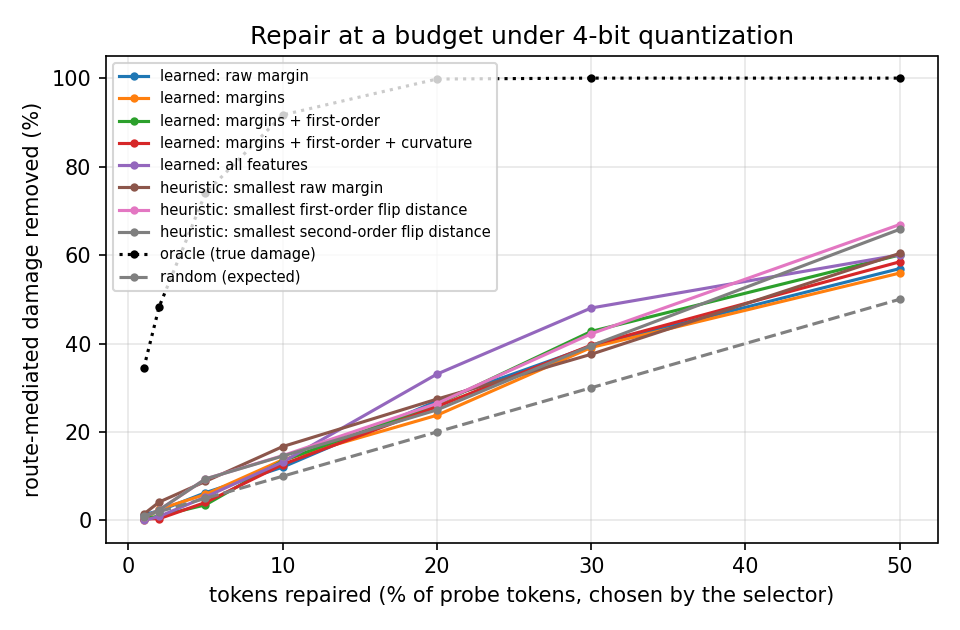

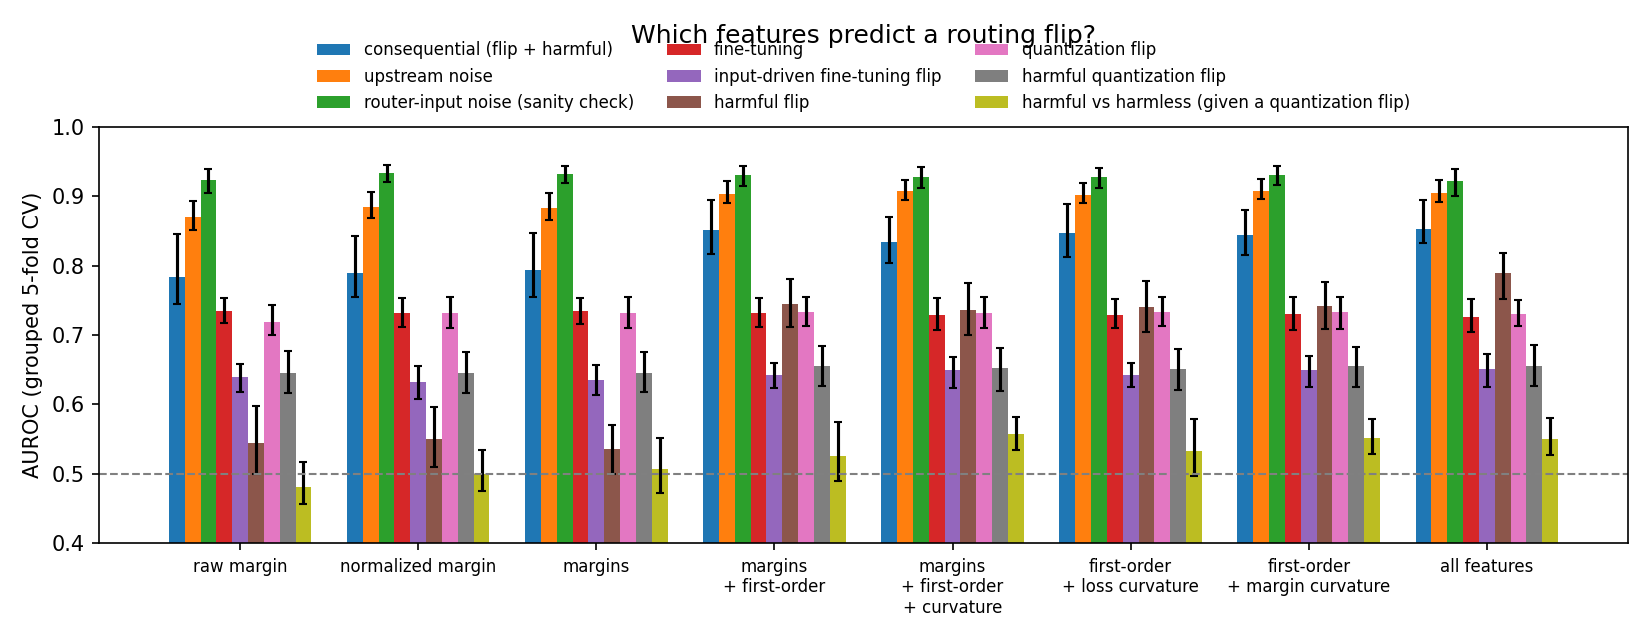

In [13]:
sig = pd.read_csv('/kaggle/working/nova_base/results/exp_granite/significance.csv'); display(sig[sig.baseline == 'margins + first-order'])
rc = pd.read_csv('/kaggle/working/nova_base/results/exp_granite/repair_curve.csv')
display(rc[rc.budget.isin([0.05, 0.1, 0.2])].pivot(index='selector', columns='budget', values='recovered_share'))
from IPython.display import Image
display(Image('/kaggle/working/nova_base/results/exp_granite/repair_curve.png')); display(Image('/kaggle/working/nova_base/results/exp_granite/auroc_by_feature_set.png'))

## Closed-form flip probability (Proposition 2)
The second-order probability has a lower Brier score at every noise level (p ≤ 0.010) and roughly halves the calibration error at large noise, confirming the result on our model.

,sigma_rel,n,measured_flip_rate,brier_first,brier_second,delta_brier,delta_brier_lo,delta_brier_hi,p_second_not_better,ece_first,ece_second,spearman_first,spearman_second,auroc_first,auroc_second
0,0.05,1024,0.0813,0.01275,0.01127,0.00148,0.00026,0.00265,0.010,0.0347,0.0211,0.7296,0.7172,0.9531,0.9585
1,0.10,1024,0.1836,0.03730,0.03054,0.00676,0.00289,0.01093,0.001,0.0959,0.0505,0.7916,0.7573,0.9185,0.9053
2,0.20,1024,0.4441,0.15735,0.10219,0.05515,0.04567,0.06515,0.001,0.2945,0.1632,0.6805,0.6181,0.8328,0.8072
3,0.40,1024,0.9011,0.50002,0.31858,0.18144,0.16326,0.19923,0.001,0.6734,0.4923,0.2945,0.1992,0.7203,0.6737


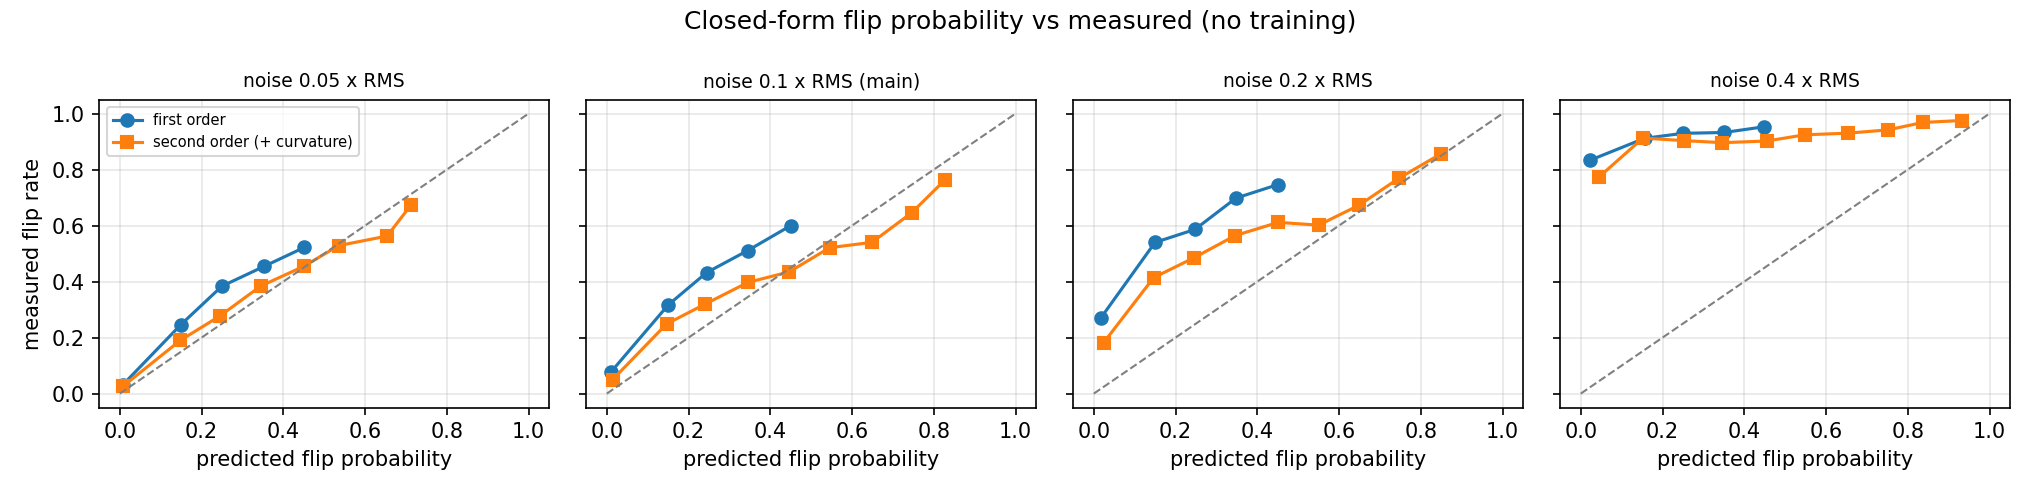

In [14]:
display(pd.read_csv('/kaggle/working/nova_base/results/exp_granite/analytic_flip.csv'))
display(Image('/kaggle/working/nova_base/results/exp_granite/calibration_analytic.png'))

## Why instruction tuning moved tokens to other experts
Instruction tuning changed the top-8 set of 37-51% of tokens; 47-60% of these flips are caused by the changed router input and 6-11% by changed router weights, the same pattern as in our model.

In [15]:
pd.read_csv('/kaggle/working/nova_base/results/exp_granite/ft_flip_causes.csv')

,layer,flipped_tokens,flip_rate_all_tokens,share: router input changed,share: router weights changed,share: either change alone flips,share: only both changes together flip
0,3,748,0.3652,0.4893,0.0882,0.3008,0.1217
1,9,994,0.4854,0.5322,0.0845,0.2827,0.1006
2,15,986,0.4814,0.5974,0.0558,0.2373,0.1095
3,21,1042,0.5088,0.4712,0.1123,0.3282,0.0883
